In [1]:
import pickle
import pandas as pd
import scipy as sp
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['start'] = pd.to_numeric(DHS_metadata['start'])
DHS_metadata['end'] = pd.to_numeric(DHS_metadata['end'])
DHS_metadata.head()

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component
0,chr1,16140,16200,1.10011,0.129388,1,16170,16170,16170,Tissue invariant
1,chr1,51868,52040,1.10021,0.0800339,1,51970,51970,51970,Placental / trophoblast
2,chr1,57280,57354,1.10025,0.2732505,4,57350,57350,57350,Neural
3,chr1,66370,66482,1.10027,0.183715575,8,66430,66410,66430,Primitive / embryonic
4,chr1,79100,79231,1.1003,0.113049,2,79150,79150,79150,Placental / trophoblast


**Lupus**

**Significant Data**

In [3]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_lupus_to_DHS_CT20211123.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [4]:
cols = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [5]:
lupus_kp_df = pd.DataFrame(to_dataframe_trait, columns = cols)

In [3]:
DHS_meta = DHS_metadata[['identifier', 'component']]
DHS_meta['ind'] = DHS_meta.index
DHS_meta = DHS_meta.set_index('identifier')
DHS_meta_ind = DHS_meta['ind']
DHS_meta_ind_dict = DHS_meta_ind.to_dict()
DHS_meta_comp = DHS_meta['component']
DHS_meta_comp_dict = DHS_meta_comp.to_dict()

/tmp/ipykernel_180940/2249616465.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  DHS_meta['ind'] = DHS_meta.index


In [7]:
for i in range(1, 4):
    lupus_dhs_id = np.array(list(lupus_kp_df['dhs' + str(i) + ' id']))
    lupus_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(lupus_dhs_id)
    lupus_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(lupus_dhs_id)
    lupus_kp_df['dhs' + str(i) + ' ind'] = lupus_dhs_ind
    lupus_kp_df['dhs' + str(i) + ' comp'] = lupus_dhs_comp

**Non-Significant Data**

In [8]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_lupus_to_DHS_CT20211123.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [9]:
cols5 = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id', 'dhs5 chr', 'dhs5 start', 'dhs5 end', 'dhs5 id']

In [10]:
lupus_full_df = pd.DataFrame(to_dataframe_trait, columns = cols5)

In [11]:
for i in range(1, 6):
    lupus_dhs_id = np.array(list(lupus_full_df['dhs' + str(i) + ' id']))
    lupus_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(lupus_dhs_id)
    lupus_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(lupus_dhs_id)
    lupus_full_df['dhs' + str(i) + ' ind'] = lupus_dhs_ind
    lupus_full_df['dhs' + str(i) + ' comp'] = lupus_dhs_comp

In [12]:
lupus_full_df[['pval mlog']] = lupus_full_df[['pval mlog']].astype(float)

In [13]:
lupus_5e_7_df = lupus_full_df[lupus_full_df['pval mlog']>(-np.log(5e-7))]
lupus_5e_6_df = lupus_full_df[(lupus_full_df['pval mlog']>(-np.log(5e-6))) & (lupus_full_df['pval mlog']<=(-np.log(5e-7)))]
lupus_5e_5_df = lupus_full_df[(lupus_full_df['pval mlog']>(-np.log(5e-5))) & (lupus_full_df['pval mlog']<=(-np.log(5e-6)))]
lupus_5e_4_df = lupus_full_df[(lupus_full_df['pval mlog']>(-np.log(5e-4))) & (lupus_full_df['pval mlog']<=(-np.log(5e-5)))]
lupus_5e_3_df = lupus_full_df[(lupus_full_df['pval mlog']>(-np.log(5e-3))) & (lupus_full_df['pval mlog']<=(-np.log(5e-4)))]
lupus_5e_2_df = lupus_full_df[(lupus_full_df['pval mlog']>(-np.log(5e-2))) & (lupus_full_df['pval mlog']<=(-np.log(5e-3)))]
lupus_5e_1_df = lupus_full_df[(lupus_full_df['pval mlog']>(-np.log(5e-1))) & (lupus_full_df['pval mlog']<=(-np.log(5e-2)))]
lupus_5e_0_df = lupus_full_df[(lupus_full_df['pval mlog']<=(-np.log(5e-1)))]

**Model Recommendations**

In [14]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_lupus_to_DHS_CT20211208.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [15]:
#for recs where I included p-value and original rank
cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'p-value', 'original rank', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [16]:
# cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id']

In [17]:
lupus_recs_df = pd.DataFrame(to_dataframe_trait, columns = cols)

In [18]:
for i in range(1, 4):
    lupus_dhs_id = np.array(list(lupus_recs_df['dhs' + str(i) + ' id']))
    lupus_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(lupus_dhs_id)
    lupus_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(lupus_dhs_id)
    lupus_recs_df['dhs' + str(i) + ' ind'] = lupus_dhs_ind
    lupus_recs_df['dhs' + str(i) + ' comp'] = lupus_dhs_comp

In [19]:
#new
lupus_recs_df['p-value'] = lupus_recs_df['p-value'].astype(float)

In [19]:
eighth = round(len(lupus_recs_df)/8)
# eighth = 100
lupus_recs_1_df = lupus_recs_df.loc[:eighth]
lupus_recs_2_df = lupus_recs_df.loc[eighth:2*eighth]
lupus_recs_3_df = lupus_recs_df.loc[2*eighth:3*eighth]
lupus_recs_4_df = lupus_recs_df.loc[3*eighth:4*eighth]
lupus_recs_5_df = lupus_recs_df.loc[4*eighth:5*eighth]
lupus_recs_6_df = lupus_recs_df.loc[5*eighth:6*eighth]
lupus_recs_7_df = lupus_recs_df.loc[6*eighth:7*eighth]
lupus_recs_8_df = lupus_recs_df.loc[7*eighth:]

In [20]:
#binning recs by p-value
lupus_recs_1_df = lupus_recs_df[lupus_recs_df['p-value']<(5e-7)]
lupus_recs_2_df = lupus_recs_df[(lupus_recs_df['p-value']>=(5e-7)) & (lupus_recs_df['p-value']<(5e-6))]
lupus_recs_3_df = lupus_recs_df[(lupus_recs_df['p-value']>=(5e-6)) & (lupus_recs_df['p-value']<(5e-5))]
lupus_recs_4_df = lupus_recs_df[(lupus_recs_df['p-value']>=(5e-5)) & (lupus_recs_df['p-value']<(5e-4))]
lupus_recs_5_df = lupus_recs_df[(lupus_recs_df['p-value']>=(5e-4)) & (lupus_recs_df['p-value']<(5e-3))]
lupus_recs_6_df = lupus_recs_df[(lupus_recs_df['p-value']>=(5e-3)) & (lupus_recs_df['p-value']<(5e-2))]
lupus_recs_7_df = lupus_recs_df[(lupus_recs_df['p-value']>=(5e-2)) & (lupus_recs_df['p-value']<(5e-1))]
lupus_recs_8_df = lupus_recs_df[(lupus_recs_df['p-value']>=(5e-1))]

**Plotting**

In [23]:
comps = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

official_order = np.array([6, 4, 14, 8, 11, 13, 2, 7, 12, 1, 3, 5, 15, 10, 9, 0])
color = np.array(color)[official_order]
comps = np.array(comps)[official_order]

In [22]:
lupus_recs_1_comp_breakdown = []
for comp in comps:
    lupus_recs_1_comp_breakdown.append(len(lupus_recs_1_df[lupus_recs_1_df['dhs1 comp']==comp])/len(lupus_recs_1_df))
    
lupus_recs_2_comp_breakdown = []
for comp in comps:
    lupus_recs_2_comp_breakdown.append(len(lupus_recs_2_df[lupus_recs_2_df['dhs1 comp']==comp])/len(lupus_recs_2_df))
    
lupus_recs_3_comp_breakdown = []
for comp in comps:
    lupus_recs_3_comp_breakdown.append(len(lupus_recs_3_df[lupus_recs_3_df['dhs1 comp']==comp])/len(lupus_recs_3_df))
    
lupus_recs_4_comp_breakdown = []
for comp in comps:
    lupus_recs_4_comp_breakdown.append(len(lupus_recs_4_df[lupus_recs_4_df['dhs1 comp']==comp])/len(lupus_recs_4_df))
    
lupus_recs_5_comp_breakdown = []
for comp in comps:
    lupus_recs_5_comp_breakdown.append(len(lupus_recs_5_df[lupus_recs_5_df['dhs1 comp']==comp])/len(lupus_recs_5_df))
    
lupus_recs_6_comp_breakdown = []
for comp in comps:
    lupus_recs_6_comp_breakdown.append(len(lupus_recs_6_df[lupus_recs_6_df['dhs1 comp']==comp])/len(lupus_recs_6_df))
    
lupus_recs_7_comp_breakdown = []
for comp in comps:
    lupus_recs_7_comp_breakdown.append(len(lupus_recs_7_df[lupus_recs_7_df['dhs1 comp']==comp])/len(lupus_recs_7_df))
    
lupus_recs_8_comp_breakdown = []
for comp in comps:
    lupus_recs_8_comp_breakdown.append(len(lupus_recs_8_df[lupus_recs_8_df['dhs1 comp']==comp])/len(lupus_recs_8_df))

In [23]:
kp_comp_breakdown = []
for comp in comps:
    kp_comp_breakdown.append(len(lupus_kp_df[lupus_kp_df['dhs1 comp']==comp])/len(lupus_kp_df))

In [24]:
lupus_5e_7_comp_breakdown = []
for comp in comps:
    lupus_5e_7_comp_breakdown.append(len(lupus_5e_7_df[lupus_5e_7_df['dhs1 comp']==comp])/len(lupus_5e_7_df))
    
lupus_5e_6_comp_breakdown = []
for comp in comps:
    lupus_5e_6_comp_breakdown.append(len(lupus_5e_6_df[lupus_5e_6_df['dhs1 comp']==comp])/len(lupus_5e_6_df))
    
lupus_5e_5_comp_breakdown = []
for comp in comps:
    lupus_5e_5_comp_breakdown.append(len(lupus_5e_5_df[lupus_5e_5_df['dhs1 comp']==comp])/len(lupus_5e_5_df))
    
lupus_5e_4_comp_breakdown = []
for comp in comps:
    lupus_5e_4_comp_breakdown.append(len(lupus_5e_4_df[lupus_5e_4_df['dhs1 comp']==comp])/len(lupus_5e_4_df))
    
lupus_5e_3_comp_breakdown = []
for comp in comps:
    lupus_5e_3_comp_breakdown.append(len(lupus_5e_3_df[lupus_5e_3_df['dhs1 comp']==comp])/len(lupus_5e_3_df))
    
lupus_5e_2_comp_breakdown = []
for comp in comps:
    lupus_5e_2_comp_breakdown.append(len(lupus_5e_2_df[lupus_5e_2_df['dhs1 comp']==comp])/len(lupus_5e_2_df))
    
lupus_5e_1_comp_breakdown = []
for comp in comps:
    lupus_5e_1_comp_breakdown.append(len(lupus_5e_1_df[lupus_5e_1_df['dhs1 comp']==comp])/len(lupus_5e_1_df))
    
lupus_5e_0_comp_breakdown = []
for comp in comps:
    lupus_5e_0_comp_breakdown.append(len(lupus_5e_0_df[lupus_5e_0_df['dhs1 comp']==comp])/len(lupus_5e_0_df))

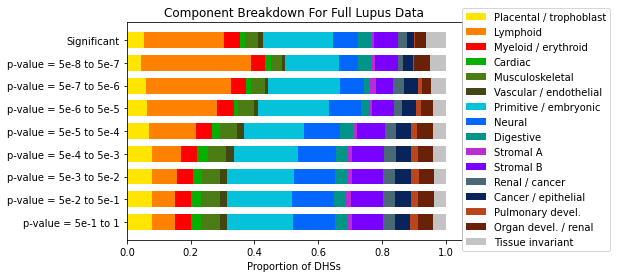

In [25]:
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']
width = 0.7

fig = plt.figure()
fig.patch.set_facecolor('white')
left_num = 0
for i in range(len(lupus_5e_0_comp_breakdown)):
    plt.barh(dataset[8], lupus_5e_0_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_5e_0_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_5e_1_comp_breakdown)):
    plt.barh(dataset[7], lupus_5e_1_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_5e_1_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_5e_2_comp_breakdown)):
    plt.barh(dataset[6], lupus_5e_2_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_5e_2_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_5e_3_comp_breakdown)):
    plt.barh(dataset[5], lupus_5e_3_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_5e_3_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_5e_4_comp_breakdown)):
    plt.barh(dataset[4], lupus_5e_4_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_5e_4_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_5e_5_comp_breakdown)):
    plt.barh(dataset[3], lupus_5e_5_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_5e_5_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_5e_6_comp_breakdown)):
    plt.barh(dataset[2], lupus_5e_6_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_5e_6_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_5e_7_comp_breakdown)):
    plt.barh(dataset[1], lupus_5e_7_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_5e_7_comp_breakdown[i]
    
left_num = 0
for i in range(len(kp_comp_breakdown)):
    plt.barh(dataset[0], kp_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += kp_comp_breakdown[i]



plt.xlabel('Proportion of DHSs')
plt.title('Component Breakdown For Full Lupus Data')
plt.legend(comps, loc = (1, -0.05))

plt.show()

In [26]:
q = np.array(lupus_5e_0_comp_breakdown)
p1 = np.array(kp_comp_breakdown)
lupus_sigdata_kl1 = p1*np.log2(p1/q)
#KL divergence of full data (relative to lupus_5e_0_comp_breakdown)
p2 = np.array(lupus_5e_7_comp_breakdown)
p3 = np.array(lupus_5e_6_comp_breakdown)
p4 = np.array(lupus_5e_5_comp_breakdown)
p5 = np.array(lupus_5e_4_comp_breakdown)
p6 = np.array(lupus_5e_3_comp_breakdown)
p7 = np.array(lupus_5e_2_comp_breakdown)
p8 = np.array(lupus_5e_1_comp_breakdown)
p9 = np.array(lupus_5e_0_comp_breakdown)

lupus_fulldata_kl2 = p2*np.log2(p2/q)
lupus_fulldata_kl3 = p3*np.log2(p3/q)
lupus_fulldata_kl4 = p4*np.log2(p4/q)
lupus_fulldata_kl5 = p5*np.log2(p5/q)
lupus_fulldata_kl6 = p6*np.log2(p6/q)
lupus_fulldata_kl7 = p7*np.log2(p7/q)
lupus_fulldata_kl8 = p8*np.log2(p8/q)
lupus_fulldata_kl9 = p9*np.log2(p9/q)

#KL divergence of recommendations (still relative to lupus_5e_0_comp_breakdown)
p2 = np.array(lupus_recs_1_comp_breakdown)
p3 = np.array(lupus_recs_2_comp_breakdown)
p4 = np.array(lupus_recs_3_comp_breakdown)
p5 = np.array(lupus_recs_4_comp_breakdown)
p6 = np.array(lupus_recs_5_comp_breakdown)
p7 = np.array(lupus_recs_6_comp_breakdown)
p8 = np.array(lupus_recs_7_comp_breakdown)
p9 = np.array(lupus_recs_8_comp_breakdown)

lupus_recs_kl2 = p2*np.log2(p2/q)
lupus_recs_kl3 = p3*np.log2(p3/q)
lupus_recs_kl4 = p4*np.log2(p4/q)
lupus_recs_kl5 = p5*np.log2(p5/q)
lupus_recs_kl6 = p6*np.log2(p6/q)
lupus_recs_kl7 = p7*np.log2(p7/q)
lupus_recs_kl8 = p8*np.log2(p8/q)
lupus_recs_kl9 = p9*np.log2(p9/q)

/tmp/ipykernel_152347/3081204172.py:36: RuntimeWarning: divide by zero encountered in log2
  lupus_recs_kl5 = p5*np.log2(p5/q)
/tmp/ipykernel_152347/3081204172.py:36: RuntimeWarning: invalid value encountered in multiply
  lupus_recs_kl5 = p5*np.log2(p5/q)
/tmp/ipykernel_152347/3081204172.py:37: RuntimeWarning: divide by zero encountered in log2
  lupus_recs_kl6 = p6*np.log2(p6/q)
/tmp/ipykernel_152347/3081204172.py:37: RuntimeWarning: invalid value encountered in multiply
  lupus_recs_kl6 = p6*np.log2(p6/q)


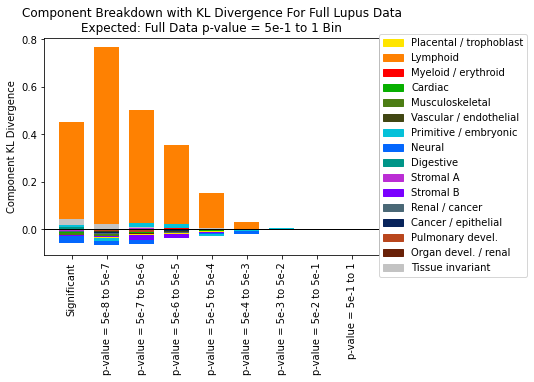

In [27]:
fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

lupus_sigdata_kl1_sorted = np.argsort(-np.absolute(lupus_sigdata_kl1))
for i in lupus_sigdata_kl1_sorted:
    plt.bar(dataset[0], lupus_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

lupus_fulldata_kl2_sorted = np.argsort(-np.absolute(lupus_fulldata_kl2))
for i in lupus_fulldata_kl2_sorted:
    plt.bar(dataset[1], lupus_fulldata_kl2[i], width=width, label=comps[i], color=color[i])
    
lupus_fulldata_kl3_sorted = np.argsort(-np.absolute(lupus_fulldata_kl3))
for i in lupus_fulldata_kl3_sorted:
    plt.bar(dataset[2], lupus_fulldata_kl3[i], width=width, label=comps[i], color=color[i])

lupus_fulldata_kl4_sorted = np.argsort(-np.absolute(lupus_fulldata_kl4))
for i in lupus_fulldata_kl4_sorted:
    plt.bar(dataset[3], lupus_fulldata_kl4[i], width=width, label=comps[i], color=color[i])

lupus_fulldata_kl5_sorted = np.argsort(-np.absolute(lupus_fulldata_kl5))
for i in lupus_fulldata_kl5_sorted:
    plt.bar(dataset[4], lupus_fulldata_kl5[i], width=width, label=comps[i], color=color[i])

lupus_fulldata_kl6_sorted = np.argsort(-np.absolute(lupus_fulldata_kl6))
for i in lupus_fulldata_kl6_sorted:
    plt.bar(dataset[5], lupus_fulldata_kl6[i], width=width, label=comps[i], color=color[i])

lupus_fulldata_kl7_sorted = np.argsort(-np.absolute(lupus_fulldata_kl7))
for i in lupus_fulldata_kl7_sorted:
    plt.bar(dataset[6], lupus_fulldata_kl7[i], width=width, label=comps[i], color=color[i])

lupus_fulldata_kl8_sorted = np.argsort(-np.absolute(lupus_fulldata_kl8))
for i in lupus_fulldata_kl8_sorted:
    plt.bar(dataset[7], lupus_fulldata_kl8[i], width=width, label=comps[i], color=color[i])

lupus_fulldata_kl9_sorted = np.argsort(-np.absolute(lupus_fulldata_kl9))
for i in lupus_fulldata_kl9_sorted:
    plt.bar(dataset[8], lupus_fulldata_kl9[i], width=width, label=comps[i], color=color[i])


    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For Full Lupus Data\nExpected: Full Data p-value = 5e-1 to 1 Bin')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

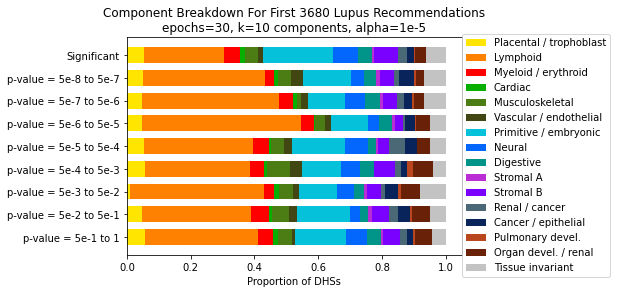

In [28]:
dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']


width = 0.7

fig = plt.figure()
fig.patch.set_facecolor('white')

left_num = 0
for i in range(len(lupus_recs_8_comp_breakdown)):
    plt.barh(dataset[8], lupus_recs_8_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_recs_8_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_recs_7_comp_breakdown)):
    plt.barh(dataset[7], lupus_recs_7_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_recs_7_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_recs_6_comp_breakdown)):
    plt.barh(dataset[6], lupus_recs_6_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_recs_6_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_recs_5_comp_breakdown)):
    plt.barh(dataset[5], lupus_recs_5_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_recs_5_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_recs_4_comp_breakdown)):
    plt.barh(dataset[4], lupus_recs_4_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_recs_4_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_recs_3_comp_breakdown)):
    plt.barh(dataset[3], lupus_recs_3_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_recs_3_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_recs_2_comp_breakdown)):
    plt.barh(dataset[2], lupus_recs_2_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_recs_2_comp_breakdown[i]

left_num = 0
for i in range(len(lupus_recs_1_comp_breakdown)):
    plt.barh(dataset[1], lupus_recs_1_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += lupus_recs_1_comp_breakdown[i]

    
left_num = 0
for i in range(len(kp_comp_breakdown)):
    plt.barh(dataset[0], kp_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += kp_comp_breakdown[i]


plt.xlabel('Proportion of DHSs')
plt.title('Component Breakdown For First 3680 Lupus Recommendations\nepochs=30, k=10 components, alpha=1e-5')
plt.legend(comps, loc = (1, -0.1))

plt.show()

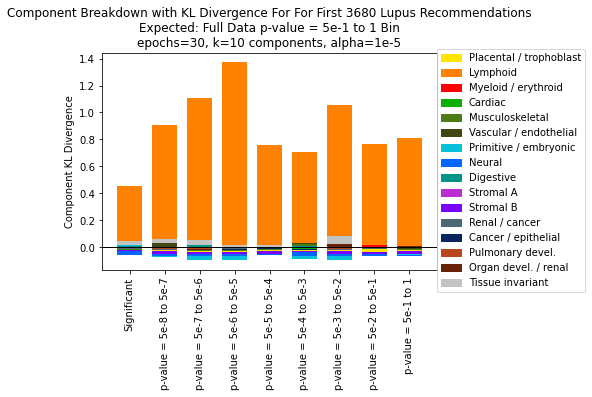

In [29]:
fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'Recommendations 1-100', 'Recommendations 101-200', 'Recommendations 201-300', 'Recommendations 301-400', 'Recommendations 401-500', 'Recommendations 501-600', 'Recommendations 601-700', 'Recommendations 701-800']
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']


width=0.7

lupus_sigdata_kl1_sorted = np.argsort(-np.absolute(lupus_sigdata_kl1))
for i in lupus_sigdata_kl1_sorted:
    plt.bar(dataset[0], lupus_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl2_sorted = np.argsort(-np.absolute(lupus_recs_kl2))
for i in lupus_recs_kl2_sorted:
    plt.bar(dataset[1], lupus_recs_kl2[i], width=width, label=comps[i], color=color[i])
    
lupus_recs_kl3_sorted = np.argsort(-np.absolute(lupus_recs_kl3))
for i in lupus_recs_kl3_sorted:
    plt.bar(dataset[2], lupus_recs_kl3[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl4_sorted = np.argsort(-np.absolute(lupus_recs_kl4))
for i in lupus_recs_kl4_sorted:
    plt.bar(dataset[3], lupus_recs_kl4[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl5_sorted = np.argsort(-np.absolute(lupus_recs_kl5))
for i in lupus_recs_kl5_sorted:
    plt.bar(dataset[4], lupus_recs_kl5[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl6_sorted = np.argsort(-np.absolute(lupus_recs_kl6))
for i in lupus_recs_kl6_sorted:
    plt.bar(dataset[5], lupus_recs_kl6[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl7_sorted = np.argsort(-np.absolute(lupus_recs_kl7))
for i in lupus_recs_kl7_sorted:
    plt.bar(dataset[6], lupus_recs_kl7[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl8_sorted = np.argsort(-np.absolute(lupus_recs_kl8))
for i in lupus_recs_kl8_sorted:
    plt.bar(dataset[7], lupus_recs_kl8[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl9_sorted = np.argsort(-np.absolute(lupus_recs_kl9))
for i in lupus_recs_kl9_sorted:
    plt.bar(dataset[8], lupus_recs_kl9[i], width=width, label=comps[i], color=color[i])

    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For For First 3680 Lupus Recommendations\nExpected: Full Data p-value = 5e-1 to 1 Bin\nepochs=30, k=10 components, alpha=1e-5')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

/tmp/ipykernel_152347/4024649798.py:18: RuntimeWarning: divide by zero encountered in log2
  lupus_recs_kl5 = p5*np.log2(p5/q)
/tmp/ipykernel_152347/4024649798.py:18: RuntimeWarning: invalid value encountered in multiply
  lupus_recs_kl5 = p5*np.log2(p5/q)
/tmp/ipykernel_152347/4024649798.py:19: RuntimeWarning: divide by zero encountered in log2
  lupus_recs_kl6 = p6*np.log2(p6/q)
/tmp/ipykernel_152347/4024649798.py:19: RuntimeWarning: invalid value encountered in multiply
  lupus_recs_kl6 = p6*np.log2(p6/q)


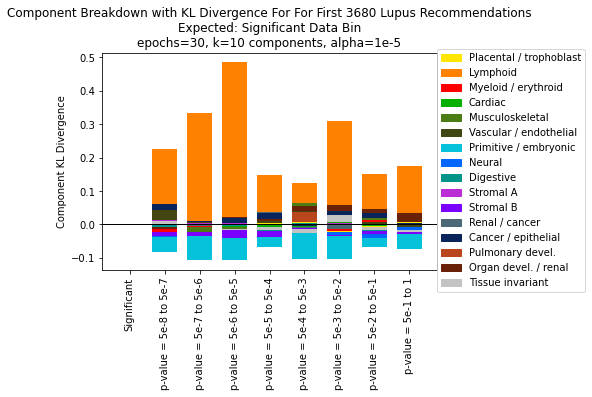

In [30]:
q = np.array(kp_comp_breakdown)

#KL divergence of recommendations (relative to kp_comp_breakdown)
p1 = np.array(kp_comp_breakdown)
p2 = np.array(lupus_recs_1_comp_breakdown)
p3 = np.array(lupus_recs_2_comp_breakdown)
p4 = np.array(lupus_recs_3_comp_breakdown)
p5 = np.array(lupus_recs_4_comp_breakdown)
p6 = np.array(lupus_recs_5_comp_breakdown)
p7 = np.array(lupus_recs_6_comp_breakdown)
p8 = np.array(lupus_recs_7_comp_breakdown)
p9 = np.array(lupus_recs_8_comp_breakdown)

lupus_sigdata_kl1 = p1*np.log2(p1/q)
lupus_recs_kl2 = p2*np.log2(p2/q)
lupus_recs_kl3 = p3*np.log2(p3/q)
lupus_recs_kl4 = p4*np.log2(p4/q)
lupus_recs_kl5 = p5*np.log2(p5/q)
lupus_recs_kl6 = p6*np.log2(p6/q)
lupus_recs_kl7 = p7*np.log2(p7/q)
lupus_recs_kl8 = p8*np.log2(p8/q)
lupus_recs_kl9 = p9*np.log2(p9/q)

fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'Recommendations 1-100', 'Recommendations 101-200', 'Recommendations 201-300', 'Recommendations 301-400', 'Recommendations 401-500', 'Recommendations 501-600', 'Recommendations 601-700', 'Recommendations 701-800']
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']


width=0.7

lupus_sigdata_kl1_sorted = np.argsort(-np.absolute(lupus_sigdata_kl1))
for i in lupus_sigdata_kl1_sorted:
    plt.bar(dataset[0], lupus_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl2_sorted = np.argsort(-np.absolute(lupus_recs_kl2))
for i in lupus_recs_kl2_sorted:
    plt.bar(dataset[1], lupus_recs_kl2[i], width=width, label=comps[i], color=color[i])
    
lupus_recs_kl3_sorted = np.argsort(-np.absolute(lupus_recs_kl3))
for i in lupus_recs_kl3_sorted:
    plt.bar(dataset[2], lupus_recs_kl3[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl4_sorted = np.argsort(-np.absolute(lupus_recs_kl4))
for i in lupus_recs_kl4_sorted:
    plt.bar(dataset[3], lupus_recs_kl4[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl5_sorted = np.argsort(-np.absolute(lupus_recs_kl5))
for i in lupus_recs_kl5_sorted:
    plt.bar(dataset[4], lupus_recs_kl5[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl6_sorted = np.argsort(-np.absolute(lupus_recs_kl6))
for i in lupus_recs_kl6_sorted:
    plt.bar(dataset[5], lupus_recs_kl6[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl7_sorted = np.argsort(-np.absolute(lupus_recs_kl7))
for i in lupus_recs_kl7_sorted:
    plt.bar(dataset[6], lupus_recs_kl7[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl8_sorted = np.argsort(-np.absolute(lupus_recs_kl8))
for i in lupus_recs_kl8_sorted:
    plt.bar(dataset[7], lupus_recs_kl8[i], width=width, label=comps[i], color=color[i])

lupus_recs_kl9_sorted = np.argsort(-np.absolute(lupus_recs_kl9))
for i in lupus_recs_kl9_sorted:
    plt.bar(dataset[8], lupus_recs_kl9[i], width=width, label=comps[i], color=color[i])

    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For For First 3680 Lupus Recommendations\nExpected: Significant Data Bin\nepochs=30, k=10 components, alpha=1e-5')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

In [31]:
#new model
lupus_recs_1_comp_breakdown_np = np.array(lupus_recs_1_comp_breakdown)
kp_comp_breakdown_np = np.array(kp_comp_breakdown)
print(kp_comp_breakdown_np-lupus_recs_1_comp_breakdown_np)

new_difference = kp_comp_breakdown_np-lupus_recs_1_comp_breakdown_np
new_difference = np.absolute(new_difference)
np.sum(new_difference)

[ 0.00199445 -0.12816428  0.0204992   0.00142798 -0.00037765 -0.02025137
  0.07012451  0.03754057  0.00502744 -0.00600696  0.03139199  0.01237977
 -0.02828819 -0.00040125  0.01049153 -0.00738774]


0.3817548828701245

In [107]:
#original model
lupus_recs_1_comp_breakdown_np = np.array(lupus_recs_1_comp_breakdown)
kp_comp_breakdown_np = np.array(kp_comp_breakdown)
print(kp_comp_breakdown_np-lupus_recs_1_comp_breakdown_np)

original_difference = kp_comp_breakdown_np-lupus_recs_1_comp_breakdown_np
original_difference = np.absolute(original_difference)
np.sum(original_difference)

[-0.03005603  0.11141581 -0.00841813 -0.00950153 -0.01498624 -0.00194855
  0.00136543 -0.00457538  0.00358177 -0.00405384 -0.00532418 -0.00338287
 -0.01619887 -0.00911595 -0.01782131  0.00901987]


0.25076576094383274

**Mean corpuscular haemoglobin concentration**

**Significant Data**

In [98]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_mean_corpuscular_haemoglobin_concentration_to_DHS_CT20211123.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [99]:
cols = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [100]:
mean_corpuscular_haemoglobin_concentration_kp_df = pd.DataFrame(to_dataframe_trait, columns = cols)

In [101]:
for i in range(1, 4):
    mean_corpuscular_haemoglobin_concentration_dhs_id = np.array(list(mean_corpuscular_haemoglobin_concentration_kp_df['dhs' + str(i) + ' id']))
    mean_corpuscular_haemoglobin_concentration_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(mean_corpuscular_haemoglobin_concentration_dhs_id)
    mean_corpuscular_haemoglobin_concentration_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(mean_corpuscular_haemoglobin_concentration_dhs_id)
    mean_corpuscular_haemoglobin_concentration_kp_df['dhs' + str(i) + ' ind'] = mean_corpuscular_haemoglobin_concentration_dhs_ind
    mean_corpuscular_haemoglobin_concentration_kp_df['dhs' + str(i) + ' comp'] = mean_corpuscular_haemoglobin_concentration_dhs_comp

**Non-Significant Data**

In [102]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_mean_corpuscular_haemoglobin_concentration_to_DHS_CT20211123.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [103]:
cols5 = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id', 'dhs5 chr', 'dhs5 start', 'dhs5 end', 'dhs5 id']

In [104]:
mean_corpuscular_haemoglobin_concentration_full_df = pd.DataFrame(to_dataframe_trait, columns = cols5)

In [105]:
for i in range(1, 6):
    mean_corpuscular_haemoglobin_concentration_dhs_id = np.array(list(mean_corpuscular_haemoglobin_concentration_full_df['dhs' + str(i) + ' id']))
    mean_corpuscular_haemoglobin_concentration_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(mean_corpuscular_haemoglobin_concentration_dhs_id)
    mean_corpuscular_haemoglobin_concentration_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(mean_corpuscular_haemoglobin_concentration_dhs_id)
    mean_corpuscular_haemoglobin_concentration_full_df['dhs' + str(i) + ' ind'] = mean_corpuscular_haemoglobin_concentration_dhs_ind
    mean_corpuscular_haemoglobin_concentration_full_df['dhs' + str(i) + ' comp'] = mean_corpuscular_haemoglobin_concentration_dhs_comp

In [106]:
mean_corpuscular_haemoglobin_concentration_full_df[['pval mlog']] = mean_corpuscular_haemoglobin_concentration_full_df[['pval mlog']].astype(float)

In [107]:
mean_corpuscular_haemoglobin_concentration_5e_7_df = mean_corpuscular_haemoglobin_concentration_full_df[mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']>(-np.log(5e-7))]
mean_corpuscular_haemoglobin_concentration_5e_6_df = mean_corpuscular_haemoglobin_concentration_full_df[(mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']>(-np.log(5e-6))) & (mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']<=(-np.log(5e-7)))]
mean_corpuscular_haemoglobin_concentration_5e_5_df = mean_corpuscular_haemoglobin_concentration_full_df[(mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']>(-np.log(5e-5))) & (mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']<=(-np.log(5e-6)))]
mean_corpuscular_haemoglobin_concentration_5e_4_df = mean_corpuscular_haemoglobin_concentration_full_df[(mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']>(-np.log(5e-4))) & (mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']<=(-np.log(5e-5)))]
mean_corpuscular_haemoglobin_concentration_5e_3_df = mean_corpuscular_haemoglobin_concentration_full_df[(mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']>(-np.log(5e-3))) & (mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']<=(-np.log(5e-4)))]
mean_corpuscular_haemoglobin_concentration_5e_2_df = mean_corpuscular_haemoglobin_concentration_full_df[(mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']>(-np.log(5e-2))) & (mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']<=(-np.log(5e-3)))]
mean_corpuscular_haemoglobin_concentration_5e_1_df = mean_corpuscular_haemoglobin_concentration_full_df[(mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']>(-np.log(5e-1))) & (mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']<=(-np.log(5e-2)))]
mean_corpuscular_haemoglobin_concentration_5e_0_df = mean_corpuscular_haemoglobin_concentration_full_df[(mean_corpuscular_haemoglobin_concentration_full_df['pval mlog']<=(-np.log(5e-1)))]

**Model Recommendations**

In [108]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_mean_corpuscular_haemoglobin_concentration_to_DHS_CT20211208.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [109]:
# cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id']

In [110]:
#for recs where I included p-value and original rank
cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'p-value', 'original rank', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [111]:
mean_corpuscular_haemoglobin_concentration_recs_df = pd.DataFrame(to_dataframe_trait, columns = cols)

In [112]:
for i in range(1, 4):
    mean_corpuscular_haemoglobin_concentration_dhs_id = np.array(list(mean_corpuscular_haemoglobin_concentration_recs_df['dhs' + str(i) + ' id']))
    mean_corpuscular_haemoglobin_concentration_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(mean_corpuscular_haemoglobin_concentration_dhs_id)
    mean_corpuscular_haemoglobin_concentration_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(mean_corpuscular_haemoglobin_concentration_dhs_id)
    mean_corpuscular_haemoglobin_concentration_recs_df['dhs' + str(i) + ' ind'] = mean_corpuscular_haemoglobin_concentration_dhs_ind
    mean_corpuscular_haemoglobin_concentration_recs_df['dhs' + str(i) + ' comp'] = mean_corpuscular_haemoglobin_concentration_dhs_comp

In [113]:
mean_corpuscular_haemoglobin_concentration_recs_df['p-value'] = mean_corpuscular_haemoglobin_concentration_recs_df['p-value'].astype(float)

In [86]:
eighth = round(len(mean_corpuscular_haemoglobin_concentration_recs_df)/8)
# eighth = 100
mean_corpuscular_haemoglobin_concentration_recs_1_df = mean_corpuscular_haemoglobin_concentration_recs_df.loc[:eighth]
mean_corpuscular_haemoglobin_concentration_recs_2_df = mean_corpuscular_haemoglobin_concentration_recs_df.loc[eighth:2*eighth]
mean_corpuscular_haemoglobin_concentration_recs_3_df = mean_corpuscular_haemoglobin_concentration_recs_df.loc[2*eighth:3*eighth]
mean_corpuscular_haemoglobin_concentration_recs_4_df = mean_corpuscular_haemoglobin_concentration_recs_df.loc[3*eighth:4*eighth]
mean_corpuscular_haemoglobin_concentration_recs_5_df = mean_corpuscular_haemoglobin_concentration_recs_df.loc[4*eighth:5*eighth]
mean_corpuscular_haemoglobin_concentration_recs_6_df = mean_corpuscular_haemoglobin_concentration_recs_df.loc[5*eighth:6*eighth]
mean_corpuscular_haemoglobin_concentration_recs_7_df = mean_corpuscular_haemoglobin_concentration_recs_df.loc[6*eighth:7*eighth]
mean_corpuscular_haemoglobin_concentration_recs_8_df = mean_corpuscular_haemoglobin_concentration_recs_df.loc[7*eighth:]

In [114]:
#binning recs by p-value
mean_corpuscular_haemoglobin_concentration_recs_1_df = mean_corpuscular_haemoglobin_concentration_recs_df[mean_corpuscular_haemoglobin_concentration_recs_df['p-value']<(5e-7)]
mean_corpuscular_haemoglobin_concentration_recs_2_df = mean_corpuscular_haemoglobin_concentration_recs_df[(mean_corpuscular_haemoglobin_concentration_recs_df['p-value']>=(5e-7)) & (mean_corpuscular_haemoglobin_concentration_recs_df['p-value']<(5e-6))]
mean_corpuscular_haemoglobin_concentration_recs_3_df = mean_corpuscular_haemoglobin_concentration_recs_df[(mean_corpuscular_haemoglobin_concentration_recs_df['p-value']>=(5e-6)) & (mean_corpuscular_haemoglobin_concentration_recs_df['p-value']<(5e-5))]
mean_corpuscular_haemoglobin_concentration_recs_4_df = mean_corpuscular_haemoglobin_concentration_recs_df[(mean_corpuscular_haemoglobin_concentration_recs_df['p-value']>=(5e-5)) & (mean_corpuscular_haemoglobin_concentration_recs_df['p-value']<(5e-4))]
mean_corpuscular_haemoglobin_concentration_recs_5_df = mean_corpuscular_haemoglobin_concentration_recs_df[(mean_corpuscular_haemoglobin_concentration_recs_df['p-value']>=(5e-4)) & (mean_corpuscular_haemoglobin_concentration_recs_df['p-value']<(5e-3))]
mean_corpuscular_haemoglobin_concentration_recs_6_df = mean_corpuscular_haemoglobin_concentration_recs_df[(mean_corpuscular_haemoglobin_concentration_recs_df['p-value']>=(5e-3)) & (mean_corpuscular_haemoglobin_concentration_recs_df['p-value']<(5e-2))]
mean_corpuscular_haemoglobin_concentration_recs_7_df = mean_corpuscular_haemoglobin_concentration_recs_df[(mean_corpuscular_haemoglobin_concentration_recs_df['p-value']>=(5e-2)) & (mean_corpuscular_haemoglobin_concentration_recs_df['p-value']<(5e-1))]
mean_corpuscular_haemoglobin_concentration_recs_8_df = mean_corpuscular_haemoglobin_concentration_recs_df[(mean_corpuscular_haemoglobin_concentration_recs_df['p-value']>=(5e-1))]

**Plotting**

In [115]:
mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_recs_1_df[mean_corpuscular_haemoglobin_concentration_recs_1_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_recs_1_df))
    
mean_corpuscular_haemoglobin_concentration_recs_2_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_recs_2_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_recs_2_df[mean_corpuscular_haemoglobin_concentration_recs_2_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_recs_2_df))
    
mean_corpuscular_haemoglobin_concentration_recs_3_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_recs_3_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_recs_3_df[mean_corpuscular_haemoglobin_concentration_recs_3_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_recs_3_df))
    
mean_corpuscular_haemoglobin_concentration_recs_4_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_recs_4_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_recs_4_df[mean_corpuscular_haemoglobin_concentration_recs_4_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_recs_4_df))
    
mean_corpuscular_haemoglobin_concentration_recs_5_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_recs_5_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_recs_5_df[mean_corpuscular_haemoglobin_concentration_recs_5_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_recs_5_df))
    
mean_corpuscular_haemoglobin_concentration_recs_6_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_recs_6_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_recs_6_df[mean_corpuscular_haemoglobin_concentration_recs_6_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_recs_6_df))
    
mean_corpuscular_haemoglobin_concentration_recs_7_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_recs_7_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_recs_7_df[mean_corpuscular_haemoglobin_concentration_recs_7_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_recs_7_df))
    
mean_corpuscular_haemoglobin_concentration_recs_8_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_recs_8_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_recs_8_df[mean_corpuscular_haemoglobin_concentration_recs_8_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_recs_8_df))

In [116]:
mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_kp_df[mean_corpuscular_haemoglobin_concentration_kp_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_kp_df))

In [117]:
mean_corpuscular_haemoglobin_concentration_5e_7_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_5e_7_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_5e_7_df[mean_corpuscular_haemoglobin_concentration_5e_7_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_5e_7_df))
    
mean_corpuscular_haemoglobin_concentration_5e_6_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_5e_6_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_5e_6_df[mean_corpuscular_haemoglobin_concentration_5e_6_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_5e_6_df))
    
mean_corpuscular_haemoglobin_concentration_5e_5_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_5e_5_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_5e_5_df[mean_corpuscular_haemoglobin_concentration_5e_5_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_5e_5_df))
    
mean_corpuscular_haemoglobin_concentration_5e_4_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_5e_4_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_5e_4_df[mean_corpuscular_haemoglobin_concentration_5e_4_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_5e_4_df))
    
mean_corpuscular_haemoglobin_concentration_5e_3_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_5e_3_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_5e_3_df[mean_corpuscular_haemoglobin_concentration_5e_3_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_5e_3_df))
    
mean_corpuscular_haemoglobin_concentration_5e_2_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_5e_2_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_5e_2_df[mean_corpuscular_haemoglobin_concentration_5e_2_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_5e_2_df))
    
mean_corpuscular_haemoglobin_concentration_5e_1_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_5e_1_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_5e_1_df[mean_corpuscular_haemoglobin_concentration_5e_1_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_5e_1_df))
    
mean_corpuscular_haemoglobin_concentration_5e_0_comp_breakdown = []
for comp in comps:
    mean_corpuscular_haemoglobin_concentration_5e_0_comp_breakdown.append(len(mean_corpuscular_haemoglobin_concentration_5e_0_df[mean_corpuscular_haemoglobin_concentration_5e_0_df['dhs1 comp']==comp])/len(mean_corpuscular_haemoglobin_concentration_5e_0_df))

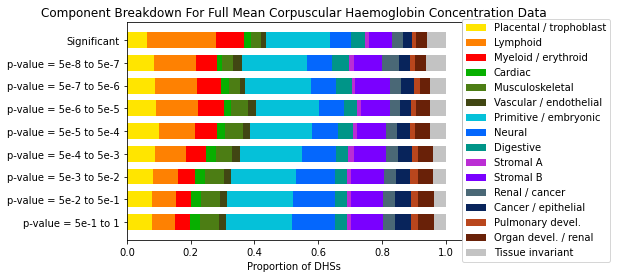

In [118]:
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']
width = 0.7

fig = plt.figure()
fig.patch.set_facecolor('white')

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_5e_0_comp_breakdown)):
    plt.barh(dataset[8], mean_corpuscular_haemoglobin_concentration_5e_0_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_5e_0_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_5e_1_comp_breakdown)):
    plt.barh(dataset[7], mean_corpuscular_haemoglobin_concentration_5e_1_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_5e_1_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_5e_2_comp_breakdown)):
    plt.barh(dataset[6], mean_corpuscular_haemoglobin_concentration_5e_2_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_5e_2_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_5e_3_comp_breakdown)):
    plt.barh(dataset[5], mean_corpuscular_haemoglobin_concentration_5e_3_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_5e_3_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_5e_4_comp_breakdown)):
    plt.barh(dataset[4], mean_corpuscular_haemoglobin_concentration_5e_4_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_5e_4_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_5e_5_comp_breakdown)):
    plt.barh(dataset[3], mean_corpuscular_haemoglobin_concentration_5e_5_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_5e_5_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_5e_6_comp_breakdown)):
    plt.barh(dataset[2], mean_corpuscular_haemoglobin_concentration_5e_6_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_5e_6_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_5e_7_comp_breakdown)):
    plt.barh(dataset[1], mean_corpuscular_haemoglobin_concentration_5e_7_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_5e_7_comp_breakdown[i]
    
left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown)):
    plt.barh(dataset[0], mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown[i]



plt.xlabel('Proportion of DHSs')
plt.title('Component Breakdown For Full Mean Corpuscular Haemoglobin Concentration Data')
plt.legend(comps, loc = (1, -0.1))

plt.show()

In [120]:
q = np.array(mean_corpuscular_haemoglobin_concentration_5e_0_comp_breakdown)
p1 = np.array(mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown)
mean_corpuscular_haemoglobin_concentration_sigdata_kl1 = p1*np.log2(p1/q)
#KL divergence of full data (relative to mean_corpuscular_haemoglobin_concentration_5e_0_comp_breakdown)
p2 = np.array(mean_corpuscular_haemoglobin_concentration_5e_7_comp_breakdown)
p3 = np.array(mean_corpuscular_haemoglobin_concentration_5e_6_comp_breakdown)
p4 = np.array(mean_corpuscular_haemoglobin_concentration_5e_5_comp_breakdown)
p5 = np.array(mean_corpuscular_haemoglobin_concentration_5e_4_comp_breakdown)
p6 = np.array(mean_corpuscular_haemoglobin_concentration_5e_3_comp_breakdown)
p7 = np.array(mean_corpuscular_haemoglobin_concentration_5e_2_comp_breakdown)
p8 = np.array(mean_corpuscular_haemoglobin_concentration_5e_1_comp_breakdown)
p9 = np.array(mean_corpuscular_haemoglobin_concentration_5e_0_comp_breakdown)

mean_corpuscular_haemoglobin_concentration_fulldata_kl2 = p2*np.log2(p2/q)
mean_corpuscular_haemoglobin_concentration_fulldata_kl3 = p3*np.log2(p3/q)
mean_corpuscular_haemoglobin_concentration_fulldata_kl4 = p4*np.log2(p4/q)
mean_corpuscular_haemoglobin_concentration_fulldata_kl5 = p5*np.log2(p5/q)
mean_corpuscular_haemoglobin_concentration_fulldata_kl6 = p6*np.log2(p6/q)
mean_corpuscular_haemoglobin_concentration_fulldata_kl7 = p7*np.log2(p7/q)
mean_corpuscular_haemoglobin_concentration_fulldata_kl8 = p8*np.log2(p8/q)
mean_corpuscular_haemoglobin_concentration_fulldata_kl9 = p9*np.log2(p9/q)

#KL divergence of recommendations (still relative to mean_corpuscular_haemoglobin_concentration_5e_0_comp_breakdown)
p2 = np.array(mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown)
p3 = np.array(mean_corpuscular_haemoglobin_concentration_recs_2_comp_breakdown)
p4 = np.array(mean_corpuscular_haemoglobin_concentration_recs_3_comp_breakdown)
p5 = np.array(mean_corpuscular_haemoglobin_concentration_recs_4_comp_breakdown)
p6 = np.array(mean_corpuscular_haemoglobin_concentration_recs_5_comp_breakdown)
p7 = np.array(mean_corpuscular_haemoglobin_concentration_recs_6_comp_breakdown)
p8 = np.array(mean_corpuscular_haemoglobin_concentration_recs_7_comp_breakdown)
p9 = np.array(mean_corpuscular_haemoglobin_concentration_recs_8_comp_breakdown)

mean_corpuscular_haemoglobin_concentration_recs_kl2 = p2*np.log2(p2/q)
mean_corpuscular_haemoglobin_concentration_recs_kl3 = p3*np.log2(p3/q)
mean_corpuscular_haemoglobin_concentration_recs_kl4 = p4*np.log2(p4/q)
mean_corpuscular_haemoglobin_concentration_recs_kl5 = p5*np.log2(p5/q)
mean_corpuscular_haemoglobin_concentration_recs_kl6 = p6*np.log2(p6/q)
mean_corpuscular_haemoglobin_concentration_recs_kl7 = p7*np.log2(p7/q)
mean_corpuscular_haemoglobin_concentration_recs_kl8 = p8*np.log2(p8/q)
mean_corpuscular_haemoglobin_concentration_recs_kl9 = p9*np.log2(p9/q)

/tmp/ipykernel_152347/2726296750.py:35: RuntimeWarning: divide by zero encountered in log2
  mean_corpuscular_haemoglobin_concentration_recs_kl4 = p4*np.log2(p4/q)
/tmp/ipykernel_152347/2726296750.py:35: RuntimeWarning: invalid value encountered in multiply
  mean_corpuscular_haemoglobin_concentration_recs_kl4 = p4*np.log2(p4/q)


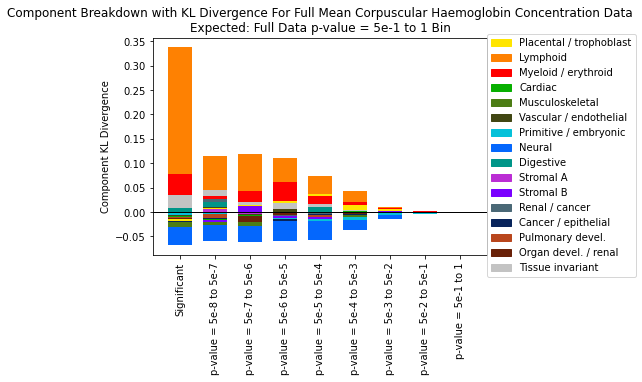

In [121]:
fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

mean_corpuscular_haemoglobin_concentration_sigdata_kl1_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_sigdata_kl1))
for i in mean_corpuscular_haemoglobin_concentration_sigdata_kl1_sorted:
    plt.bar(dataset[0], mean_corpuscular_haemoglobin_concentration_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_fulldata_kl2_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_fulldata_kl2))
for i in mean_corpuscular_haemoglobin_concentration_fulldata_kl2_sorted:
    plt.bar(dataset[1], mean_corpuscular_haemoglobin_concentration_fulldata_kl2[i], width=width, label=comps[i], color=color[i])
    
mean_corpuscular_haemoglobin_concentration_fulldata_kl3_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_fulldata_kl3))
for i in mean_corpuscular_haemoglobin_concentration_fulldata_kl3_sorted:
    plt.bar(dataset[2], mean_corpuscular_haemoglobin_concentration_fulldata_kl3[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_fulldata_kl4_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_fulldata_kl4))
for i in mean_corpuscular_haemoglobin_concentration_fulldata_kl4_sorted:
    plt.bar(dataset[3], mean_corpuscular_haemoglobin_concentration_fulldata_kl4[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_fulldata_kl5_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_fulldata_kl5))
for i in mean_corpuscular_haemoglobin_concentration_fulldata_kl5_sorted:
    plt.bar(dataset[4], mean_corpuscular_haemoglobin_concentration_fulldata_kl5[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_fulldata_kl6_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_fulldata_kl6))
for i in mean_corpuscular_haemoglobin_concentration_fulldata_kl6_sorted:
    plt.bar(dataset[5], mean_corpuscular_haemoglobin_concentration_fulldata_kl6[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_fulldata_kl7_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_fulldata_kl7))
for i in mean_corpuscular_haemoglobin_concentration_fulldata_kl7_sorted:
    plt.bar(dataset[6], mean_corpuscular_haemoglobin_concentration_fulldata_kl7[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_fulldata_kl8_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_fulldata_kl8))
for i in mean_corpuscular_haemoglobin_concentration_fulldata_kl8_sorted:
    plt.bar(dataset[7], mean_corpuscular_haemoglobin_concentration_fulldata_kl8[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_fulldata_kl9_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_fulldata_kl9))
for i in mean_corpuscular_haemoglobin_concentration_fulldata_kl9_sorted:
    plt.bar(dataset[8], mean_corpuscular_haemoglobin_concentration_fulldata_kl9[i], width=width, label=comps[i], color=color[i])


    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For Full Mean Corpuscular Haemoglobin Concentration Data\nExpected: Full Data p-value = 5e-1 to 1 Bin')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

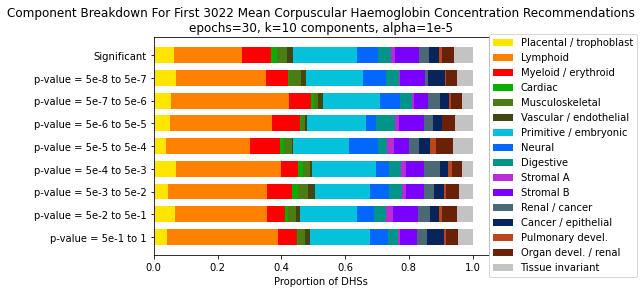

In [122]:
dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width = 0.7

fig = plt.figure()
fig.patch.set_facecolor('white')

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_recs_8_comp_breakdown)):
    plt.barh(dataset[8], mean_corpuscular_haemoglobin_concentration_recs_8_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_recs_8_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_recs_7_comp_breakdown)):
    plt.barh(dataset[7], mean_corpuscular_haemoglobin_concentration_recs_7_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_recs_7_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_recs_6_comp_breakdown)):
    plt.barh(dataset[6], mean_corpuscular_haemoglobin_concentration_recs_6_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_recs_6_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_recs_5_comp_breakdown)):
    plt.barh(dataset[5], mean_corpuscular_haemoglobin_concentration_recs_5_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_recs_5_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_recs_4_comp_breakdown)):
    plt.barh(dataset[4], mean_corpuscular_haemoglobin_concentration_recs_4_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_recs_4_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_recs_3_comp_breakdown)):
    plt.barh(dataset[3], mean_corpuscular_haemoglobin_concentration_recs_3_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_recs_3_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_recs_2_comp_breakdown)):
    plt.barh(dataset[2], mean_corpuscular_haemoglobin_concentration_recs_2_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_recs_2_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown)):
    plt.barh(dataset[1], mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown[i]

left_num = 0
for i in range(len(mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown)):
    plt.barh(dataset[0], mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown[i]


plt.xlabel('Proportion of DHSs')
plt.title('Component Breakdown For First 3022 Mean Corpuscular Haemoglobin Concentration Recommendations\nepochs=30, k=10 components, alpha=1e-5')
plt.legend(comps, loc = (1, -0.1))

plt.show()

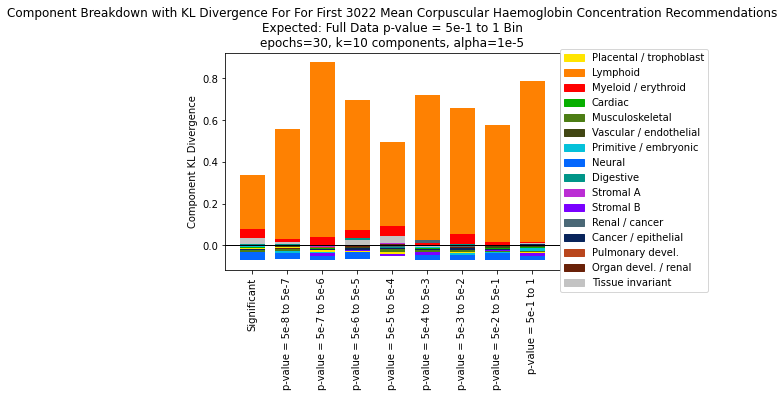

In [123]:
fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'Recommendations 1-100', 'Recommendations 101-200', 'Recommendations 201-300', 'Recommendations 301-400', 'Recommendations 401-500', 'Recommendations 501-600', 'Recommendations 601-700', 'Recommendations 701-800']
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

mean_corpuscular_haemoglobin_concentration_sigdata_kl1_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_sigdata_kl1))
for i in mean_corpuscular_haemoglobin_concentration_sigdata_kl1_sorted:
    plt.bar(dataset[0], mean_corpuscular_haemoglobin_concentration_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl2_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl2))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl2_sorted:
    plt.bar(dataset[1], mean_corpuscular_haemoglobin_concentration_recs_kl2[i], width=width, label=comps[i], color=color[i])
    
mean_corpuscular_haemoglobin_concentration_recs_kl3_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl3))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl3_sorted:
    plt.bar(dataset[2], mean_corpuscular_haemoglobin_concentration_recs_kl3[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl4_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl4))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl4_sorted:
    plt.bar(dataset[3], mean_corpuscular_haemoglobin_concentration_recs_kl4[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl5_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl5))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl5_sorted:
    plt.bar(dataset[4], mean_corpuscular_haemoglobin_concentration_recs_kl5[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl6_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl6))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl6_sorted:
    plt.bar(dataset[5], mean_corpuscular_haemoglobin_concentration_recs_kl6[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl7_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl7))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl7_sorted:
    plt.bar(dataset[6], mean_corpuscular_haemoglobin_concentration_recs_kl7[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl8_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl8))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl8_sorted:
    plt.bar(dataset[7], mean_corpuscular_haemoglobin_concentration_recs_kl8[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl9_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl9))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl9_sorted:
    plt.bar(dataset[8], mean_corpuscular_haemoglobin_concentration_recs_kl9[i], width=width, label=comps[i], color=color[i])

    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For For First 3022 Mean Corpuscular Haemoglobin Concentration Recommendations\nExpected: Full Data p-value = 5e-1 to 1 Bin\nepochs=30, k=10 components, alpha=1e-5')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

/tmp/ipykernel_152347/72514617.py:17: RuntimeWarning: divide by zero encountered in log2
  mean_corpuscular_haemoglobin_concentration_recs_kl4 = p4*np.log2(p4/q)
/tmp/ipykernel_152347/72514617.py:17: RuntimeWarning: invalid value encountered in multiply
  mean_corpuscular_haemoglobin_concentration_recs_kl4 = p4*np.log2(p4/q)


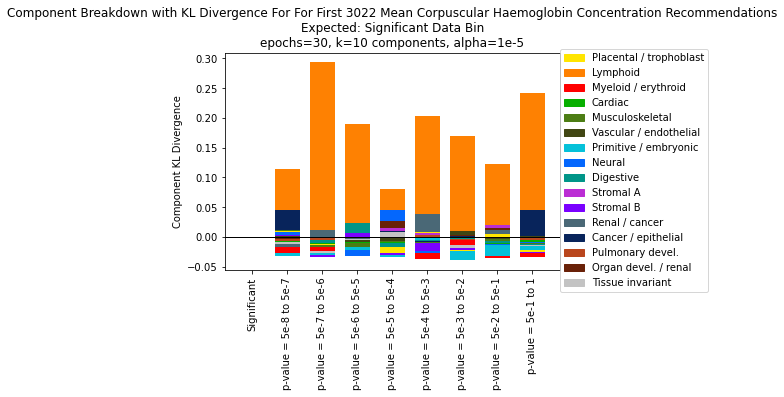

In [124]:
q = np.array(mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown)

#KL divergence of recommendations (relative to mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown)
p1 = np.array(mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown)
p2 = np.array(mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown)
p3 = np.array(mean_corpuscular_haemoglobin_concentration_recs_2_comp_breakdown)
p4 = np.array(mean_corpuscular_haemoglobin_concentration_recs_3_comp_breakdown)
p5 = np.array(mean_corpuscular_haemoglobin_concentration_recs_4_comp_breakdown)
p6 = np.array(mean_corpuscular_haemoglobin_concentration_recs_5_comp_breakdown)
p7 = np.array(mean_corpuscular_haemoglobin_concentration_recs_6_comp_breakdown)
p8 = np.array(mean_corpuscular_haemoglobin_concentration_recs_7_comp_breakdown)
p9 = np.array(mean_corpuscular_haemoglobin_concentration_recs_8_comp_breakdown)

mean_corpuscular_haemoglobin_concentration_sigdata_kl1 = p1*np.log2(p1/q)
mean_corpuscular_haemoglobin_concentration_recs_kl2 = p2*np.log2(p2/q)
mean_corpuscular_haemoglobin_concentration_recs_kl3 = p3*np.log2(p3/q)
mean_corpuscular_haemoglobin_concentration_recs_kl4 = p4*np.log2(p4/q)
mean_corpuscular_haemoglobin_concentration_recs_kl5 = p5*np.log2(p5/q)
mean_corpuscular_haemoglobin_concentration_recs_kl6 = p6*np.log2(p6/q)
mean_corpuscular_haemoglobin_concentration_recs_kl7 = p7*np.log2(p7/q)
mean_corpuscular_haemoglobin_concentration_recs_kl8 = p8*np.log2(p8/q)
mean_corpuscular_haemoglobin_concentration_recs_kl9 = p9*np.log2(p9/q)

fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'Recommendations 1-100', 'Recommendations 101-200', 'Recommendations 201-300', 'Recommendations 301-400', 'Recommendations 401-500', 'Recommendations 501-600', 'Recommendations 601-700', 'Recommendations 701-800']
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

mean_corpuscular_haemoglobin_concentration_sigdata_kl1_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_sigdata_kl1))
for i in mean_corpuscular_haemoglobin_concentration_sigdata_kl1_sorted:
    plt.bar(dataset[0], mean_corpuscular_haemoglobin_concentration_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl2_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl2))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl2_sorted:
    plt.bar(dataset[1], mean_corpuscular_haemoglobin_concentration_recs_kl2[i], width=width, label=comps[i], color=color[i])
    
mean_corpuscular_haemoglobin_concentration_recs_kl3_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl3))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl3_sorted:
    plt.bar(dataset[2], mean_corpuscular_haemoglobin_concentration_recs_kl3[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl4_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl4))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl4_sorted:
    plt.bar(dataset[3], mean_corpuscular_haemoglobin_concentration_recs_kl4[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl5_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl5))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl5_sorted:
    plt.bar(dataset[4], mean_corpuscular_haemoglobin_concentration_recs_kl5[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl6_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl6))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl6_sorted:
    plt.bar(dataset[5], mean_corpuscular_haemoglobin_concentration_recs_kl6[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl7_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl7))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl7_sorted:
    plt.bar(dataset[6], mean_corpuscular_haemoglobin_concentration_recs_kl7[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl8_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl8))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl8_sorted:
    plt.bar(dataset[7], mean_corpuscular_haemoglobin_concentration_recs_kl8[i], width=width, label=comps[i], color=color[i])

mean_corpuscular_haemoglobin_concentration_recs_kl9_sorted = np.argsort(-np.absolute(mean_corpuscular_haemoglobin_concentration_recs_kl9))
for i in mean_corpuscular_haemoglobin_concentration_recs_kl9_sorted:
    plt.bar(dataset[8], mean_corpuscular_haemoglobin_concentration_recs_kl9[i], width=width, label=comps[i], color=color[i])

    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For For First 3022 Mean Corpuscular Haemoglobin Concentration Recommendations\nExpected: Significant Data Bin\nepochs=30, k=10 components, alpha=1e-5')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

In [125]:
#new model
mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown_np = np.array(mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown)
mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown_np = np.array(mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown)
print(mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown_np-mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown_np)

new_difference = mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown_np-mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown_np
new_difference = np.absolute(new_difference)
np.sum(new_difference)

[-0.00668602 -0.06855905  0.02223211  0.01770885 -0.00696352 -0.00136149
  0.02393527 -0.00556995  0.00144474  0.0090283  -0.0022703   0.02125652
 -0.0234297   0.00828425  0.00211334  0.00883665]


0.22968004218004223

In [75]:
#original model
mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown_np = np.array(mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown)
mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown_np = np.array(mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown)
print(mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown_np-mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown_np)

original_difference = mean_corpuscular_haemoglobin_concentration_kp_comp_breakdown_np-mean_corpuscular_haemoglobin_concentration_recs_1_comp_breakdown_np
original_difference = np.absolute(original_difference)
np.sum(original_difference)

[-0.02584872  0.08201904  0.01596562 -0.0058441  -0.01644993 -0.00630408
  0.00487741 -0.01498002 -0.00023208  0.00034143 -0.01802682 -0.00271424
 -0.01052623 -0.00438964 -0.00697149  0.00908385]


0.22457469885640602

**Pulse rate, automated reading**

**Significant data**

In [35]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_pulse_rate_automated_reading_to_DHS_CT20211209.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [36]:
cols = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [37]:
pulse_rate_automated_reading_kp_df = pd.DataFrame(to_dataframe_trait, columns = cols)

In [38]:
for i in range(1, 4):
    pulse_rate_automated_reading_dhs_id = np.array(list(pulse_rate_automated_reading_kp_df['dhs' + str(i) + ' id']))
    pulse_rate_automated_reading_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(pulse_rate_automated_reading_dhs_id)
    pulse_rate_automated_reading_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(pulse_rate_automated_reading_dhs_id)
    pulse_rate_automated_reading_kp_df['dhs' + str(i) + ' ind'] = pulse_rate_automated_reading_dhs_ind
    pulse_rate_automated_reading_kp_df['dhs' + str(i) + ' comp'] = pulse_rate_automated_reading_dhs_comp

**Non-significant data**

In [39]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_pulse_rate_automated_reading_to_DHS_CT20211209.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [40]:
cols5 = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id', 'dhs5 chr', 'dhs5 start', 'dhs5 end', 'dhs5 id']

In [41]:
pulse_rate_automated_reading_full_df = pd.DataFrame(to_dataframe_trait, columns = cols5)

In [42]:
for i in range(1, 6):
    pulse_rate_automated_reading_dhs_id = np.array(list(pulse_rate_automated_reading_full_df['dhs' + str(i) + ' id']))
    pulse_rate_automated_reading_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(pulse_rate_automated_reading_dhs_id)
    pulse_rate_automated_reading_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(pulse_rate_automated_reading_dhs_id)
    pulse_rate_automated_reading_full_df['dhs' + str(i) + ' ind'] = pulse_rate_automated_reading_dhs_ind
    pulse_rate_automated_reading_full_df['dhs' + str(i) + ' comp'] = pulse_rate_automated_reading_dhs_comp

In [43]:
pulse_rate_automated_reading_full_df[['pval mlog']] = pulse_rate_automated_reading_full_df[['pval mlog']].astype(float)

In [44]:
pulse_rate_automated_reading_5e_7_df = pulse_rate_automated_reading_full_df[pulse_rate_automated_reading_full_df['pval mlog']>(-np.log(5e-7))]
pulse_rate_automated_reading_5e_6_df = pulse_rate_automated_reading_full_df[(pulse_rate_automated_reading_full_df['pval mlog']>(-np.log(5e-6))) & (pulse_rate_automated_reading_full_df['pval mlog']<=(-np.log(5e-7)))]
pulse_rate_automated_reading_5e_5_df = pulse_rate_automated_reading_full_df[(pulse_rate_automated_reading_full_df['pval mlog']>(-np.log(5e-5))) & (pulse_rate_automated_reading_full_df['pval mlog']<=(-np.log(5e-6)))]
pulse_rate_automated_reading_5e_4_df = pulse_rate_automated_reading_full_df[(pulse_rate_automated_reading_full_df['pval mlog']>(-np.log(5e-4))) & (pulse_rate_automated_reading_full_df['pval mlog']<=(-np.log(5e-5)))]
pulse_rate_automated_reading_5e_3_df = pulse_rate_automated_reading_full_df[(pulse_rate_automated_reading_full_df['pval mlog']>(-np.log(5e-3))) & (pulse_rate_automated_reading_full_df['pval mlog']<=(-np.log(5e-4)))]
pulse_rate_automated_reading_5e_2_df = pulse_rate_automated_reading_full_df[(pulse_rate_automated_reading_full_df['pval mlog']>(-np.log(5e-2))) & (pulse_rate_automated_reading_full_df['pval mlog']<=(-np.log(5e-3)))]
pulse_rate_automated_reading_5e_1_df = pulse_rate_automated_reading_full_df[(pulse_rate_automated_reading_full_df['pval mlog']>(-np.log(5e-1))) & (pulse_rate_automated_reading_full_df['pval mlog']<=(-np.log(5e-2)))]
pulse_rate_automated_reading_5e_0_df = pulse_rate_automated_reading_full_df[(pulse_rate_automated_reading_full_df['pval mlog']<=(-np.log(5e-1)))]

**Model Recommendations**

In [45]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_pulse_rate_automated_reading_to_DHS_CT20211209.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [46]:
# cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id']

In [47]:
#for recs where I included p-value and original rank
cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'p-value', 'original rank', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [48]:
pulse_rate_automated_reading_recs_df = pd.DataFrame(to_dataframe_trait, columns = cols)

In [49]:
for i in range(1, 4):
    pulse_rate_automated_reading_dhs_id = np.array(list(pulse_rate_automated_reading_recs_df['dhs' + str(i) + ' id']))
    pulse_rate_automated_reading_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(pulse_rate_automated_reading_dhs_id)
    pulse_rate_automated_reading_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(pulse_rate_automated_reading_dhs_id)
    pulse_rate_automated_reading_recs_df['dhs' + str(i) + ' ind'] = pulse_rate_automated_reading_dhs_ind
    pulse_rate_automated_reading_recs_df['dhs' + str(i) + ' comp'] = pulse_rate_automated_reading_dhs_comp

In [50]:
pulse_rate_automated_reading_recs_df['p-value'] = pulse_rate_automated_reading_recs_df['p-value'].astype(float)

In [83]:
eighth = round(len(pulse_rate_automated_reading_recs_df)/8)
# eighth = 100
pulse_rate_automated_reading_recs_1_df = pulse_rate_automated_reading_recs_df.loc[:eighth]
pulse_rate_automated_reading_recs_2_df = pulse_rate_automated_reading_recs_df.loc[eighth:2*eighth]
pulse_rate_automated_reading_recs_3_df = pulse_rate_automated_reading_recs_df.loc[2*eighth:3*eighth]
pulse_rate_automated_reading_recs_4_df = pulse_rate_automated_reading_recs_df.loc[3*eighth:4*eighth]
pulse_rate_automated_reading_recs_5_df = pulse_rate_automated_reading_recs_df.loc[4*eighth:5*eighth]
pulse_rate_automated_reading_recs_6_df = pulse_rate_automated_reading_recs_df.loc[5*eighth:6*eighth]
pulse_rate_automated_reading_recs_7_df = pulse_rate_automated_reading_recs_df.loc[6*eighth:7*eighth]
pulse_rate_automated_reading_recs_8_df = pulse_rate_automated_reading_recs_df.loc[7*eighth:]

In [63]:
#binning recs by p-value
pulse_rate_automated_reading_recs_1_df = pulse_rate_automated_reading_recs_df[pulse_rate_automated_reading_recs_df['p-value']<(5e-7)]
pulse_rate_automated_reading_recs_2_df = pulse_rate_automated_reading_recs_df[(pulse_rate_automated_reading_recs_df['p-value']>=(5e-7)) & (pulse_rate_automated_reading_recs_df['p-value']<(5e-6))]
pulse_rate_automated_reading_recs_3_df = pulse_rate_automated_reading_recs_df[(pulse_rate_automated_reading_recs_df['p-value']>=(5e-6)) & (pulse_rate_automated_reading_recs_df['p-value']<(5e-5))]
pulse_rate_automated_reading_recs_4_df = pulse_rate_automated_reading_recs_df[(pulse_rate_automated_reading_recs_df['p-value']>=(5e-5)) & (pulse_rate_automated_reading_recs_df['p-value']<(5e-4))]
pulse_rate_automated_reading_recs_5_df = pulse_rate_automated_reading_recs_df[(pulse_rate_automated_reading_recs_df['p-value']>=(5e-4)) & (pulse_rate_automated_reading_recs_df['p-value']<(5e-3))]
pulse_rate_automated_reading_recs_6_df = pulse_rate_automated_reading_recs_df[(pulse_rate_automated_reading_recs_df['p-value']>=(5e-3)) & (pulse_rate_automated_reading_recs_df['p-value']<(5e-2))]
pulse_rate_automated_reading_recs_7_df = pulse_rate_automated_reading_recs_df[(pulse_rate_automated_reading_recs_df['p-value']>=(5e-2)) & (pulse_rate_automated_reading_recs_df['p-value']<(5e-1))]
pulse_rate_automated_reading_recs_8_df = pulse_rate_automated_reading_recs_df[(pulse_rate_automated_reading_recs_df['p-value']>=(5e-1))]

**Plotting**

In [84]:
pulse_rate_automated_reading_recs_1_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_recs_1_comp_breakdown.append(len(pulse_rate_automated_reading_recs_1_df[pulse_rate_automated_reading_recs_1_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_recs_1_df))
    
pulse_rate_automated_reading_recs_2_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_recs_2_comp_breakdown.append(len(pulse_rate_automated_reading_recs_2_df[pulse_rate_automated_reading_recs_2_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_recs_2_df))
    
pulse_rate_automated_reading_recs_3_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_recs_3_comp_breakdown.append(len(pulse_rate_automated_reading_recs_3_df[pulse_rate_automated_reading_recs_3_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_recs_3_df))
    
pulse_rate_automated_reading_recs_4_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_recs_4_comp_breakdown.append(len(pulse_rate_automated_reading_recs_4_df[pulse_rate_automated_reading_recs_4_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_recs_4_df))
    
pulse_rate_automated_reading_recs_5_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_recs_5_comp_breakdown.append(len(pulse_rate_automated_reading_recs_5_df[pulse_rate_automated_reading_recs_5_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_recs_5_df))
    
pulse_rate_automated_reading_recs_6_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_recs_6_comp_breakdown.append(len(pulse_rate_automated_reading_recs_6_df[pulse_rate_automated_reading_recs_6_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_recs_6_df))
    
pulse_rate_automated_reading_recs_7_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_recs_7_comp_breakdown.append(len(pulse_rate_automated_reading_recs_7_df[pulse_rate_automated_reading_recs_7_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_recs_7_df))
    
pulse_rate_automated_reading_recs_8_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_recs_8_comp_breakdown.append(len(pulse_rate_automated_reading_recs_8_df[pulse_rate_automated_reading_recs_8_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_recs_8_df))

In [85]:
pulse_rate_automated_reading_kp_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_kp_comp_breakdown.append(len(pulse_rate_automated_reading_kp_df[pulse_rate_automated_reading_kp_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_kp_df))

In [86]:
pulse_rate_automated_reading_5e_7_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_5e_7_comp_breakdown.append(len(pulse_rate_automated_reading_5e_7_df[pulse_rate_automated_reading_5e_7_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_5e_7_df))
    
pulse_rate_automated_reading_5e_6_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_5e_6_comp_breakdown.append(len(pulse_rate_automated_reading_5e_6_df[pulse_rate_automated_reading_5e_6_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_5e_6_df))
    
pulse_rate_automated_reading_5e_5_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_5e_5_comp_breakdown.append(len(pulse_rate_automated_reading_5e_5_df[pulse_rate_automated_reading_5e_5_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_5e_5_df))
    
pulse_rate_automated_reading_5e_4_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_5e_4_comp_breakdown.append(len(pulse_rate_automated_reading_5e_4_df[pulse_rate_automated_reading_5e_4_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_5e_4_df))
    
pulse_rate_automated_reading_5e_3_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_5e_3_comp_breakdown.append(len(pulse_rate_automated_reading_5e_3_df[pulse_rate_automated_reading_5e_3_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_5e_3_df))
    
pulse_rate_automated_reading_5e_2_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_5e_2_comp_breakdown.append(len(pulse_rate_automated_reading_5e_2_df[pulse_rate_automated_reading_5e_2_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_5e_2_df))
    
pulse_rate_automated_reading_5e_1_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_5e_1_comp_breakdown.append(len(pulse_rate_automated_reading_5e_1_df[pulse_rate_automated_reading_5e_1_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_5e_1_df))
    
pulse_rate_automated_reading_5e_0_comp_breakdown = []
for comp in comps:
    pulse_rate_automated_reading_5e_0_comp_breakdown.append(len(pulse_rate_automated_reading_5e_0_df[pulse_rate_automated_reading_5e_0_df['dhs1 comp']==comp])/len(pulse_rate_automated_reading_5e_0_df))

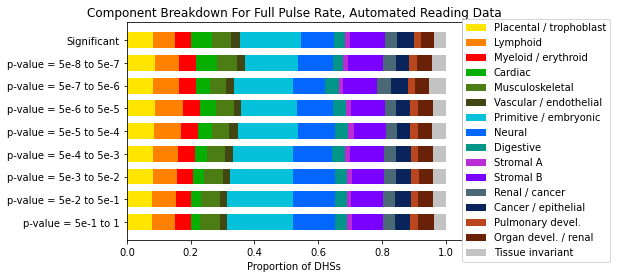

In [87]:
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']
width = 0.7

fig = plt.figure()
fig.patch.set_facecolor('white')

left_num = 0
for i in range(len(pulse_rate_automated_reading_5e_0_comp_breakdown)):
    plt.barh(dataset[8], pulse_rate_automated_reading_5e_0_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_5e_0_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_5e_1_comp_breakdown)):
    plt.barh(dataset[7], pulse_rate_automated_reading_5e_1_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_5e_1_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_5e_2_comp_breakdown)):
    plt.barh(dataset[6], pulse_rate_automated_reading_5e_2_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_5e_2_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_5e_3_comp_breakdown)):
    plt.barh(dataset[5], pulse_rate_automated_reading_5e_3_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_5e_3_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_5e_4_comp_breakdown)):
    plt.barh(dataset[4], pulse_rate_automated_reading_5e_4_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_5e_4_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_5e_5_comp_breakdown)):
    plt.barh(dataset[3], pulse_rate_automated_reading_5e_5_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_5e_5_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_5e_6_comp_breakdown)):
    plt.barh(dataset[2], pulse_rate_automated_reading_5e_6_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_5e_6_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_5e_7_comp_breakdown)):
    plt.barh(dataset[1], pulse_rate_automated_reading_5e_7_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_5e_7_comp_breakdown[i]
    
left_num = 0
for i in range(len(pulse_rate_automated_reading_kp_comp_breakdown)):
    plt.barh(dataset[0], pulse_rate_automated_reading_kp_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_kp_comp_breakdown[i]



plt.xlabel('Proportion of DHSs')
plt.title('Component Breakdown For Full Pulse Rate, Automated Reading Data')
plt.legend(comps, loc = (1, -0.1))

plt.show()

In [88]:
q = np.array(pulse_rate_automated_reading_5e_0_comp_breakdown)
p1 = np.array(pulse_rate_automated_reading_kp_comp_breakdown)
pulse_rate_automated_reading_sigdata_kl1 = p1*np.log2(p1/q)
#KL divergence of full data (relative to pulse_rate_automated_reading_5e_0_comp_breakdown)
p2 = np.array(pulse_rate_automated_reading_5e_7_comp_breakdown)
p3 = np.array(pulse_rate_automated_reading_5e_6_comp_breakdown)
p4 = np.array(pulse_rate_automated_reading_5e_5_comp_breakdown)
p5 = np.array(pulse_rate_automated_reading_5e_4_comp_breakdown)
p6 = np.array(pulse_rate_automated_reading_5e_3_comp_breakdown)
p7 = np.array(pulse_rate_automated_reading_5e_2_comp_breakdown)
p8 = np.array(pulse_rate_automated_reading_5e_1_comp_breakdown)
p9 = np.array(pulse_rate_automated_reading_5e_0_comp_breakdown)

pulse_rate_automated_reading_fulldata_kl2 = p2*np.log2(p2/q)
pulse_rate_automated_reading_fulldata_kl3 = p3*np.log2(p3/q)
pulse_rate_automated_reading_fulldata_kl4 = p4*np.log2(p4/q)
pulse_rate_automated_reading_fulldata_kl5 = p5*np.log2(p5/q)
pulse_rate_automated_reading_fulldata_kl6 = p6*np.log2(p6/q)
pulse_rate_automated_reading_fulldata_kl7 = p7*np.log2(p7/q)
pulse_rate_automated_reading_fulldata_kl8 = p8*np.log2(p8/q)
pulse_rate_automated_reading_fulldata_kl9 = p9*np.log2(p9/q)

#KL divergence of recommendations (still relative to pulse_rate_automated_reading_5e_0_comp_breakdown)
p2 = np.array(pulse_rate_automated_reading_recs_1_comp_breakdown)
p3 = np.array(pulse_rate_automated_reading_recs_2_comp_breakdown)
p4 = np.array(pulse_rate_automated_reading_recs_3_comp_breakdown)
p5 = np.array(pulse_rate_automated_reading_recs_4_comp_breakdown)
p6 = np.array(pulse_rate_automated_reading_recs_5_comp_breakdown)
p7 = np.array(pulse_rate_automated_reading_recs_6_comp_breakdown)
p8 = np.array(pulse_rate_automated_reading_recs_7_comp_breakdown)
p9 = np.array(pulse_rate_automated_reading_recs_8_comp_breakdown)

pulse_rate_automated_reading_recs_kl2 = p2*np.log2(p2/q)
pulse_rate_automated_reading_recs_kl3 = p3*np.log2(p3/q)
pulse_rate_automated_reading_recs_kl4 = p4*np.log2(p4/q)
pulse_rate_automated_reading_recs_kl5 = p5*np.log2(p5/q)
pulse_rate_automated_reading_recs_kl6 = p6*np.log2(p6/q)
pulse_rate_automated_reading_recs_kl7 = p7*np.log2(p7/q)
pulse_rate_automated_reading_recs_kl8 = p8*np.log2(p8/q)
pulse_rate_automated_reading_recs_kl9 = p9*np.log2(p9/q)

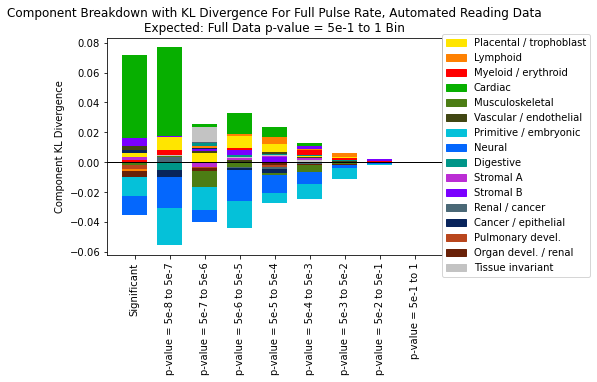

In [89]:
fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

pulse_rate_automated_reading_sigdata_kl1_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_sigdata_kl1))
for i in pulse_rate_automated_reading_sigdata_kl1_sorted:
    plt.bar(dataset[0], pulse_rate_automated_reading_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_fulldata_kl2_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_fulldata_kl2))
for i in pulse_rate_automated_reading_fulldata_kl2_sorted:
    plt.bar(dataset[1], pulse_rate_automated_reading_fulldata_kl2[i], width=width, label=comps[i], color=color[i])
    
pulse_rate_automated_reading_fulldata_kl3_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_fulldata_kl3))
for i in pulse_rate_automated_reading_fulldata_kl3_sorted:
    plt.bar(dataset[2], pulse_rate_automated_reading_fulldata_kl3[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_fulldata_kl4_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_fulldata_kl4))
for i in pulse_rate_automated_reading_fulldata_kl4_sorted:
    plt.bar(dataset[3], pulse_rate_automated_reading_fulldata_kl4[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_fulldata_kl5_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_fulldata_kl5))
for i in pulse_rate_automated_reading_fulldata_kl5_sorted:
    plt.bar(dataset[4], pulse_rate_automated_reading_fulldata_kl5[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_fulldata_kl6_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_fulldata_kl6))
for i in pulse_rate_automated_reading_fulldata_kl6_sorted:
    plt.bar(dataset[5], pulse_rate_automated_reading_fulldata_kl6[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_fulldata_kl7_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_fulldata_kl7))
for i in pulse_rate_automated_reading_fulldata_kl7_sorted:
    plt.bar(dataset[6], pulse_rate_automated_reading_fulldata_kl7[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_fulldata_kl8_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_fulldata_kl8))
for i in pulse_rate_automated_reading_fulldata_kl8_sorted:
    plt.bar(dataset[7], pulse_rate_automated_reading_fulldata_kl8[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_fulldata_kl9_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_fulldata_kl9))
for i in pulse_rate_automated_reading_fulldata_kl9_sorted:
    plt.bar(dataset[8], pulse_rate_automated_reading_fulldata_kl9[i], width=width, label=comps[i], color=color[i])


    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For Full Pulse Rate, Automated Reading Data\nExpected: Full Data p-value = 5e-1 to 1 Bin')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

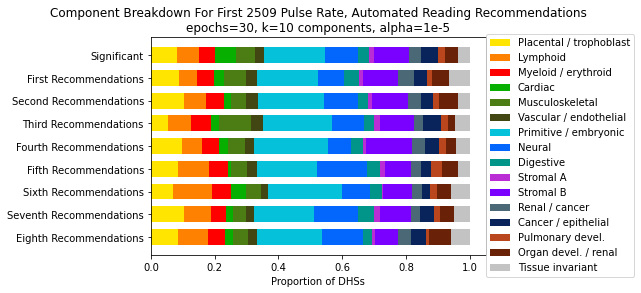

In [90]:
dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width = 0.7

fig = plt.figure()
fig.patch.set_facecolor('white')

left_num = 0
for i in range(len(pulse_rate_automated_reading_recs_8_comp_breakdown)):
    plt.barh(dataset[8], pulse_rate_automated_reading_recs_8_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_recs_8_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_recs_7_comp_breakdown)):
    plt.barh(dataset[7], pulse_rate_automated_reading_recs_7_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_recs_7_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_recs_6_comp_breakdown)):
    plt.barh(dataset[6], pulse_rate_automated_reading_recs_6_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_recs_6_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_recs_5_comp_breakdown)):
    plt.barh(dataset[5], pulse_rate_automated_reading_recs_5_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_recs_5_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_recs_4_comp_breakdown)):
    plt.barh(dataset[4], pulse_rate_automated_reading_recs_4_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_recs_4_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_recs_3_comp_breakdown)):
    plt.barh(dataset[3], pulse_rate_automated_reading_recs_3_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_recs_3_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_recs_2_comp_breakdown)):
    plt.barh(dataset[2], pulse_rate_automated_reading_recs_2_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_recs_2_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_recs_1_comp_breakdown)):
    plt.barh(dataset[1], pulse_rate_automated_reading_recs_1_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_recs_1_comp_breakdown[i]

left_num = 0
for i in range(len(pulse_rate_automated_reading_kp_comp_breakdown)):
    plt.barh(dataset[0], pulse_rate_automated_reading_kp_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += pulse_rate_automated_reading_kp_comp_breakdown[i]


plt.xlabel('Proportion of DHSs')
plt.title('Component Breakdown For First 2509 Pulse Rate, Automated Reading Recommendations\nepochs=30, k=10 components, alpha=1e-5')
plt.legend(comps, loc = (1, -0.1))

plt.show()

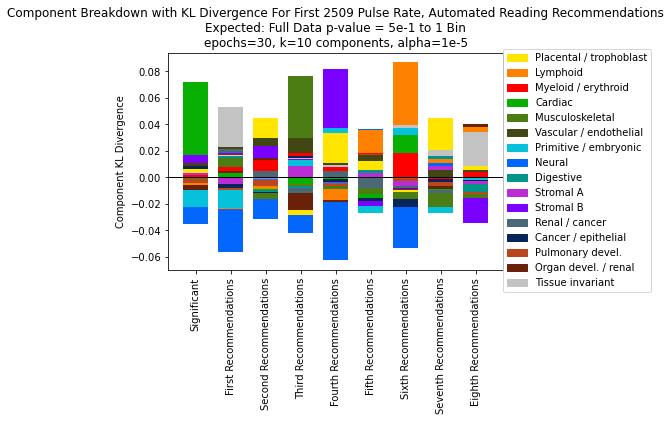

In [91]:
fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'Recommendations 1-100', 'Recommendations 101-200', 'Recommendations 201-300', 'Recommendations 301-400', 'Recommendations 401-500', 'Recommendations 501-600', 'Recommendations 601-700', 'Recommendations 701-800']
# dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

pulse_rate_automated_reading_sigdata_kl1_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_sigdata_kl1))
for i in pulse_rate_automated_reading_sigdata_kl1_sorted:
    plt.bar(dataset[0], pulse_rate_automated_reading_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl2_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl2))
for i in pulse_rate_automated_reading_recs_kl2_sorted:
    plt.bar(dataset[1], pulse_rate_automated_reading_recs_kl2[i], width=width, label=comps[i], color=color[i])
    
pulse_rate_automated_reading_recs_kl3_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl3))
for i in pulse_rate_automated_reading_recs_kl3_sorted:
    plt.bar(dataset[2], pulse_rate_automated_reading_recs_kl3[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl4_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl4))
for i in pulse_rate_automated_reading_recs_kl4_sorted:
    plt.bar(dataset[3], pulse_rate_automated_reading_recs_kl4[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl5_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl5))
for i in pulse_rate_automated_reading_recs_kl5_sorted:
    plt.bar(dataset[4], pulse_rate_automated_reading_recs_kl5[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl6_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl6))
for i in pulse_rate_automated_reading_recs_kl6_sorted:
    plt.bar(dataset[5], pulse_rate_automated_reading_recs_kl6[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl7_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl7))
for i in pulse_rate_automated_reading_recs_kl7_sorted:
    plt.bar(dataset[6], pulse_rate_automated_reading_recs_kl7[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl8_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl8))
for i in pulse_rate_automated_reading_recs_kl8_sorted:
    plt.bar(dataset[7], pulse_rate_automated_reading_recs_kl8[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl9_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl9))
for i in pulse_rate_automated_reading_recs_kl9_sorted:
    plt.bar(dataset[8], pulse_rate_automated_reading_recs_kl9[i], width=width, label=comps[i], color=color[i])

    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For First 2509 Pulse Rate, Automated Reading Recommendations\nExpected: Full Data p-value = 5e-1 to 1 Bin\nepochs=30, k=10 components, alpha=1e-5')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

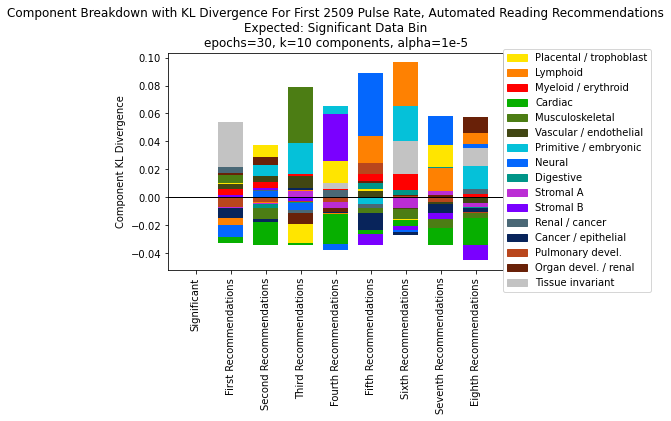

In [92]:
q = np.array(pulse_rate_automated_reading_kp_comp_breakdown)

#KL divergence of recommendations (relative to pulse_rate_automated_reading_kp_comp_breakdown)
p1 = np.array(pulse_rate_automated_reading_kp_comp_breakdown)
p2 = np.array(pulse_rate_automated_reading_recs_1_comp_breakdown)
p3 = np.array(pulse_rate_automated_reading_recs_2_comp_breakdown)
p4 = np.array(pulse_rate_automated_reading_recs_3_comp_breakdown)
p5 = np.array(pulse_rate_automated_reading_recs_4_comp_breakdown)
p6 = np.array(pulse_rate_automated_reading_recs_5_comp_breakdown)
p7 = np.array(pulse_rate_automated_reading_recs_6_comp_breakdown)
p8 = np.array(pulse_rate_automated_reading_recs_7_comp_breakdown)
p9 = np.array(pulse_rate_automated_reading_recs_8_comp_breakdown)

pulse_rate_automated_reading_sigdata_kl1 = p1*np.log2(p1/q)
pulse_rate_automated_reading_recs_kl2 = p2*np.log2(p2/q)
pulse_rate_automated_reading_recs_kl3 = p3*np.log2(p3/q)
pulse_rate_automated_reading_recs_kl4 = p4*np.log2(p4/q)
pulse_rate_automated_reading_recs_kl5 = p5*np.log2(p5/q)
pulse_rate_automated_reading_recs_kl6 = p6*np.log2(p6/q)
pulse_rate_automated_reading_recs_kl7 = p7*np.log2(p7/q)
pulse_rate_automated_reading_recs_kl8 = p8*np.log2(p8/q)
pulse_rate_automated_reading_recs_kl9 = p9*np.log2(p9/q)

fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'Recommendations 1-100', 'Recommendations 101-200', 'Recommendations 201-300', 'Recommendations 301-400', 'Recommendations 401-500', 'Recommendations 501-600', 'Recommendations 601-700', 'Recommendations 701-800']
# dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

pulse_rate_automated_reading_sigdata_kl1_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_sigdata_kl1))
for i in pulse_rate_automated_reading_sigdata_kl1_sorted:
    plt.bar(dataset[0], pulse_rate_automated_reading_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl2_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl2))
for i in pulse_rate_automated_reading_recs_kl2_sorted:
    plt.bar(dataset[1], pulse_rate_automated_reading_recs_kl2[i], width=width, label=comps[i], color=color[i])
    
pulse_rate_automated_reading_recs_kl3_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl3))
for i in pulse_rate_automated_reading_recs_kl3_sorted:
    plt.bar(dataset[2], pulse_rate_automated_reading_recs_kl3[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl4_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl4))
for i in pulse_rate_automated_reading_recs_kl4_sorted:
    plt.bar(dataset[3], pulse_rate_automated_reading_recs_kl4[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl5_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl5))
for i in pulse_rate_automated_reading_recs_kl5_sorted:
    plt.bar(dataset[4], pulse_rate_automated_reading_recs_kl5[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl6_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl6))
for i in pulse_rate_automated_reading_recs_kl6_sorted:
    plt.bar(dataset[5], pulse_rate_automated_reading_recs_kl6[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl7_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl7))
for i in pulse_rate_automated_reading_recs_kl7_sorted:
    plt.bar(dataset[6], pulse_rate_automated_reading_recs_kl7[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl8_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl8))
for i in pulse_rate_automated_reading_recs_kl8_sorted:
    plt.bar(dataset[7], pulse_rate_automated_reading_recs_kl8[i], width=width, label=comps[i], color=color[i])

pulse_rate_automated_reading_recs_kl9_sorted = np.argsort(-np.absolute(pulse_rate_automated_reading_recs_kl9))
for i in pulse_rate_automated_reading_recs_kl9_sorted:
    plt.bar(dataset[8], pulse_rate_automated_reading_recs_kl9[i], width=width, label=comps[i], color=color[i])

    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For First 2509 Pulse Rate, Automated Reading Recommendations\nExpected: Significant Data Bin\nepochs=30, k=10 components, alpha=1e-5')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

**QRS Duration**

**Significant Data**

In [4]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_known_positives_qrs_duration_to_DHS_CT20211209.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [5]:
cols = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id']

In [6]:
qrs_duration_kp_df = pd.DataFrame(to_dataframe_trait, columns = cols)

In [7]:
for i in range(1, 3):
    qrs_duration_dhs_id = np.array(list(qrs_duration_kp_df['dhs' + str(i) + ' id']))
    qrs_duration_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(qrs_duration_dhs_id)
    qrs_duration_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(qrs_duration_dhs_id)
    qrs_duration_kp_df['dhs' + str(i) + ' ind'] = qrs_duration_dhs_ind
    qrs_duration_kp_df['dhs' + str(i) + ' comp'] = qrs_duration_dhs_comp

**Non-Significant Data**

In [8]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_full_data_qrs_duration_to_DHS_CT20211209.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [9]:
cols5 = ['snp chr', 'snp start', 'snp end', 'pval', 'reference snp cluster ID', 'pval mlog', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id', 'dhs5 chr', 'dhs5 start', 'dhs5 end', 'dhs5 id']

In [10]:
qrs_duration_full_df = pd.DataFrame(to_dataframe_trait, columns = cols5)

In [11]:
for i in range(1, 6):
    qrs_duration_dhs_id = np.array(list(qrs_duration_full_df['dhs' + str(i) + ' id']))
    qrs_duration_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(qrs_duration_dhs_id)
    qrs_duration_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(qrs_duration_dhs_id)
    qrs_duration_full_df['dhs' + str(i) + ' ind'] = qrs_duration_dhs_ind
    qrs_duration_full_df['dhs' + str(i) + ' comp'] = qrs_duration_dhs_comp

In [12]:
qrs_duration_full_df[['pval mlog']] = qrs_duration_full_df[['pval mlog']].astype(float)

In [13]:
qrs_duration_5e_7_df = qrs_duration_full_df[qrs_duration_full_df['pval mlog']>(-np.log(5e-7))]
qrs_duration_5e_6_df = qrs_duration_full_df[(qrs_duration_full_df['pval mlog']>(-np.log(5e-6))) & (qrs_duration_full_df['pval mlog']<=(-np.log(5e-7)))]
qrs_duration_5e_5_df = qrs_duration_full_df[(qrs_duration_full_df['pval mlog']>(-np.log(5e-5))) & (qrs_duration_full_df['pval mlog']<=(-np.log(5e-6)))]
qrs_duration_5e_4_df = qrs_duration_full_df[(qrs_duration_full_df['pval mlog']>(-np.log(5e-4))) & (qrs_duration_full_df['pval mlog']<=(-np.log(5e-5)))]
qrs_duration_5e_3_df = qrs_duration_full_df[(qrs_duration_full_df['pval mlog']>(-np.log(5e-3))) & (qrs_duration_full_df['pval mlog']<=(-np.log(5e-4)))]
qrs_duration_5e_2_df = qrs_duration_full_df[(qrs_duration_full_df['pval mlog']>(-np.log(5e-2))) & (qrs_duration_full_df['pval mlog']<=(-np.log(5e-3)))]
qrs_duration_5e_1_df = qrs_duration_full_df[(qrs_duration_full_df['pval mlog']>(-np.log(5e-1))) & (qrs_duration_full_df['pval mlog']<=(-np.log(5e-2)))]
qrs_duration_5e_0_df = qrs_duration_full_df[(qrs_duration_full_df['pval mlog']<=(-np.log(5e-1)))]

**Model Recommendations**

In [14]:
to_dataframe_trait = []
file_path = os.path.join('/home/ctrader/Hold/GWAS/recommendations/', 'GWAS_e30_d10_reg00001_rec_info_QRS_duration_to_DHS_CT20211209.scoreSorted.txt')
with open(file_path) as f:
    for line in f:
        line = line.strip('\n')
        line = line.split('|')
        SNP = line[0]
        DHS = line[1]
        SNP = SNP.split('\t')
        to_dataframe_list = SNP
        multiple_DHS = DHS.split(';')
        for i in range(len(multiple_DHS)):
            multiple_DHS[i] = multiple_DHS[i].split('\t')
            to_dataframe_list.extend(multiple_DHS[i])
        to_dataframe_trait.append(to_dataframe_list)

In [15]:
# cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id', 'dhs4 chr', 'dhs4 start', 'dhs4 end', 'dhs4 id']

In [16]:
#for recs where I included p-value and original rank
cols = ['snp chr', 'snp start', 'snp end', 'pred score', 'reference snp cluster ID', 'p-value', 'original rank', 'dhs1 chr', 'dhs1 start', 'dhs1 end', 'dhs1 id', 'dhs2 chr', 'dhs2 start', 'dhs2 end', 'dhs2 id', 'dhs3 chr', 'dhs3 start', 'dhs3 end', 'dhs3 id']

In [17]:
qrs_duration_recs_df = pd.DataFrame(to_dataframe_trait, columns = cols)

In [18]:
for i in range(1, 4):
    qrs_duration_dhs_id = np.array(list(qrs_duration_recs_df['dhs' + str(i) + ' id']))
    qrs_duration_dhs_ind = np.vectorize(DHS_meta_ind_dict.get)(qrs_duration_dhs_id)
    qrs_duration_dhs_comp = np.vectorize(DHS_meta_comp_dict.get)(qrs_duration_dhs_id)
    qrs_duration_recs_df['dhs' + str(i) + ' ind'] = qrs_duration_dhs_ind
    qrs_duration_recs_df['dhs' + str(i) + ' comp'] = qrs_duration_dhs_comp

In [19]:
qrs_duration_recs_df['p-value'] = qrs_duration_recs_df['p-value'].astype(float)

In [86]:
eighth = round(len(qrs_duration_recs_df)/8)
# eighth = 100
qrs_duration_recs_1_df = qrs_duration_recs_df.loc[:eighth]
qrs_duration_recs_2_df = qrs_duration_recs_df.loc[eighth:2*eighth]
qrs_duration_recs_3_df = qrs_duration_recs_df.loc[2*eighth:3*eighth]
qrs_duration_recs_4_df = qrs_duration_recs_df.loc[3*eighth:4*eighth]
qrs_duration_recs_5_df = qrs_duration_recs_df.loc[4*eighth:5*eighth]
qrs_duration_recs_6_df = qrs_duration_recs_df.loc[5*eighth:6*eighth]
qrs_duration_recs_7_df = qrs_duration_recs_df.loc[6*eighth:7*eighth]
qrs_duration_recs_8_df = qrs_duration_recs_df.loc[7*eighth:]

In [48]:
#binning recs by p-value
qrs_duration_recs_1_df = qrs_duration_recs_df[qrs_duration_recs_df['p-value']<(5e-7)]
qrs_duration_recs_2_df = qrs_duration_recs_df[(qrs_duration_recs_df['p-value']>=(5e-7)) & (qrs_duration_recs_df['p-value']<(5e-6))]
qrs_duration_recs_3_df = qrs_duration_recs_df[(qrs_duration_recs_df['p-value']>=(5e-6)) & (qrs_duration_recs_df['p-value']<(5e-5))]
qrs_duration_recs_4_df = qrs_duration_recs_df[(qrs_duration_recs_df['p-value']>=(5e-5)) & (qrs_duration_recs_df['p-value']<(5e-4))]
qrs_duration_recs_5_df = qrs_duration_recs_df[(qrs_duration_recs_df['p-value']>=(5e-4)) & (qrs_duration_recs_df['p-value']<(5e-3))]
qrs_duration_recs_6_df = qrs_duration_recs_df[(qrs_duration_recs_df['p-value']>=(5e-3)) & (qrs_duration_recs_df['p-value']<(5e-2))]
qrs_duration_recs_7_df = qrs_duration_recs_df[(qrs_duration_recs_df['p-value']>=(5e-2)) & (qrs_duration_recs_df['p-value']<(5e-1))]
qrs_duration_recs_8_df = qrs_duration_recs_df[(qrs_duration_recs_df['p-value']>=(5e-1))]

**plotting**

In [87]:
qrs_duration_recs_1_comp_breakdown = []
for comp in comps:
    qrs_duration_recs_1_comp_breakdown.append(len(qrs_duration_recs_1_df[qrs_duration_recs_1_df['dhs1 comp']==comp])/len(qrs_duration_recs_1_df))
    
qrs_duration_recs_2_comp_breakdown = []
for comp in comps:
    qrs_duration_recs_2_comp_breakdown.append(len(qrs_duration_recs_2_df[qrs_duration_recs_2_df['dhs1 comp']==comp])/len(qrs_duration_recs_2_df))
    
qrs_duration_recs_3_comp_breakdown = []
for comp in comps:
    qrs_duration_recs_3_comp_breakdown.append(len(qrs_duration_recs_3_df[qrs_duration_recs_3_df['dhs1 comp']==comp])/len(qrs_duration_recs_3_df))
    
qrs_duration_recs_4_comp_breakdown = []
for comp in comps:
    qrs_duration_recs_4_comp_breakdown.append(len(qrs_duration_recs_4_df[qrs_duration_recs_4_df['dhs1 comp']==comp])/len(qrs_duration_recs_4_df))
    
qrs_duration_recs_5_comp_breakdown = []
for comp in comps:
    qrs_duration_recs_5_comp_breakdown.append(len(qrs_duration_recs_5_df[qrs_duration_recs_5_df['dhs1 comp']==comp])/len(qrs_duration_recs_5_df))
    
qrs_duration_recs_6_comp_breakdown = []
for comp in comps:
    qrs_duration_recs_6_comp_breakdown.append(len(qrs_duration_recs_6_df[qrs_duration_recs_6_df['dhs1 comp']==comp])/len(qrs_duration_recs_6_df))
    
qrs_duration_recs_7_comp_breakdown = []
for comp in comps:
    qrs_duration_recs_7_comp_breakdown.append(len(qrs_duration_recs_7_df[qrs_duration_recs_7_df['dhs1 comp']==comp])/len(qrs_duration_recs_7_df))
    
qrs_duration_recs_8_comp_breakdown = []
for comp in comps:
    qrs_duration_recs_8_comp_breakdown.append(len(qrs_duration_recs_8_df[qrs_duration_recs_8_df['dhs1 comp']==comp])/len(qrs_duration_recs_8_df))

In [88]:
qrs_duration_kp_comp_breakdown = []
for comp in comps:
    qrs_duration_kp_comp_breakdown.append(len(qrs_duration_kp_df[qrs_duration_kp_df['dhs1 comp']==comp])/len(qrs_duration_kp_df))

In [89]:
qrs_duration_5e_7_comp_breakdown = []
for comp in comps:
    qrs_duration_5e_7_comp_breakdown.append(len(qrs_duration_5e_7_df[qrs_duration_5e_7_df['dhs1 comp']==comp])/len(qrs_duration_5e_7_df))
    
qrs_duration_5e_6_comp_breakdown = []
for comp in comps:
    qrs_duration_5e_6_comp_breakdown.append(len(qrs_duration_5e_6_df[qrs_duration_5e_6_df['dhs1 comp']==comp])/len(qrs_duration_5e_6_df))
    
qrs_duration_5e_5_comp_breakdown = []
for comp in comps:
    qrs_duration_5e_5_comp_breakdown.append(len(qrs_duration_5e_5_df[qrs_duration_5e_5_df['dhs1 comp']==comp])/len(qrs_duration_5e_5_df))
    
qrs_duration_5e_4_comp_breakdown = []
for comp in comps:
    qrs_duration_5e_4_comp_breakdown.append(len(qrs_duration_5e_4_df[qrs_duration_5e_4_df['dhs1 comp']==comp])/len(qrs_duration_5e_4_df))
    
qrs_duration_5e_3_comp_breakdown = []
for comp in comps:
    qrs_duration_5e_3_comp_breakdown.append(len(qrs_duration_5e_3_df[qrs_duration_5e_3_df['dhs1 comp']==comp])/len(qrs_duration_5e_3_df))
    
qrs_duration_5e_2_comp_breakdown = []
for comp in comps:
    qrs_duration_5e_2_comp_breakdown.append(len(qrs_duration_5e_2_df[qrs_duration_5e_2_df['dhs1 comp']==comp])/len(qrs_duration_5e_2_df))
    
qrs_duration_5e_1_comp_breakdown = []
for comp in comps:
    qrs_duration_5e_1_comp_breakdown.append(len(qrs_duration_5e_1_df[qrs_duration_5e_1_df['dhs1 comp']==comp])/len(qrs_duration_5e_1_df))
    
qrs_duration_5e_0_comp_breakdown = []
for comp in comps:
    qrs_duration_5e_0_comp_breakdown.append(len(qrs_duration_5e_0_df[qrs_duration_5e_0_df['dhs1 comp']==comp])/len(qrs_duration_5e_0_df))

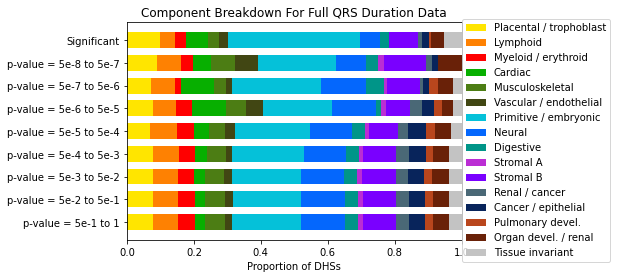

In [90]:
dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']
width = 0.7

fig = plt.figure()
fig.patch.set_facecolor('white')

left_num = 0
for i in range(len(qrs_duration_5e_0_comp_breakdown)):
    plt.barh(dataset[8], qrs_duration_5e_0_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_5e_0_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_5e_1_comp_breakdown)):
    plt.barh(dataset[7], qrs_duration_5e_1_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_5e_1_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_5e_2_comp_breakdown)):
    plt.barh(dataset[6], qrs_duration_5e_2_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_5e_2_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_5e_3_comp_breakdown)):
    plt.barh(dataset[5], qrs_duration_5e_3_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_5e_3_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_5e_4_comp_breakdown)):
    plt.barh(dataset[4], qrs_duration_5e_4_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_5e_4_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_5e_5_comp_breakdown)):
    plt.barh(dataset[3], qrs_duration_5e_5_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_5e_5_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_5e_6_comp_breakdown)):
    plt.barh(dataset[2], qrs_duration_5e_6_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_5e_6_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_5e_7_comp_breakdown)):
    plt.barh(dataset[1], qrs_duration_5e_7_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_5e_7_comp_breakdown[i]
    
left_num = 0
for i in range(len(qrs_duration_kp_comp_breakdown)):
    plt.barh(dataset[0], qrs_duration_kp_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_kp_comp_breakdown[i]



plt.xlabel('Proportion of DHSs')
plt.title('Component Breakdown For Full QRS Duration Data')
plt.legend(comps, loc = (1, -0.1))

plt.show()

In [91]:
q = np.array(qrs_duration_5e_0_comp_breakdown)
p1 = np.array(qrs_duration_kp_comp_breakdown)
qrs_duration_sigdata_kl1 = p1*np.log2(p1/q)
#KL divergence of full data (relative to qrs_duration_5e_0_comp_breakdown)
p2 = np.array(qrs_duration_5e_7_comp_breakdown)
p3 = np.array(qrs_duration_5e_6_comp_breakdown)
p4 = np.array(qrs_duration_5e_5_comp_breakdown)
p5 = np.array(qrs_duration_5e_4_comp_breakdown)
p6 = np.array(qrs_duration_5e_3_comp_breakdown)
p7 = np.array(qrs_duration_5e_2_comp_breakdown)
p8 = np.array(qrs_duration_5e_1_comp_breakdown)
p9 = np.array(qrs_duration_5e_0_comp_breakdown)

qrs_duration_fulldata_kl2 = p2*np.log2(p2/q)
qrs_duration_fulldata_kl3 = p3*np.log2(p3/q)
qrs_duration_fulldata_kl4 = p4*np.log2(p4/q)
qrs_duration_fulldata_kl5 = p5*np.log2(p5/q)
qrs_duration_fulldata_kl6 = p6*np.log2(p6/q)
qrs_duration_fulldata_kl7 = p7*np.log2(p7/q)
qrs_duration_fulldata_kl8 = p8*np.log2(p8/q)
qrs_duration_fulldata_kl9 = p9*np.log2(p9/q)

#KL divergence of recommendations (still relative to qrs_duration_5e_0_comp_breakdown)
p2 = np.array(qrs_duration_recs_1_comp_breakdown)
p3 = np.array(qrs_duration_recs_2_comp_breakdown)
p4 = np.array(qrs_duration_recs_3_comp_breakdown)
p5 = np.array(qrs_duration_recs_4_comp_breakdown)
p6 = np.array(qrs_duration_recs_5_comp_breakdown)
p7 = np.array(qrs_duration_recs_6_comp_breakdown)
p8 = np.array(qrs_duration_recs_7_comp_breakdown)
p9 = np.array(qrs_duration_recs_8_comp_breakdown)

qrs_duration_recs_kl2 = p2*np.log2(p2/q)
qrs_duration_recs_kl3 = p3*np.log2(p3/q)
qrs_duration_recs_kl4 = p4*np.log2(p4/q)
qrs_duration_recs_kl5 = p5*np.log2(p5/q)
qrs_duration_recs_kl6 = p6*np.log2(p6/q)
qrs_duration_recs_kl7 = p7*np.log2(p7/q)
qrs_duration_recs_kl8 = p8*np.log2(p8/q)
qrs_duration_recs_kl9 = p9*np.log2(p9/q)

/tmp/ipykernel_173386/398544853.py:3: RuntimeWarning: divide by zero encountered in log2
  qrs_duration_sigdata_kl1 = p1*np.log2(p1/q)
/tmp/ipykernel_173386/398544853.py:3: RuntimeWarning: invalid value encountered in multiply
  qrs_duration_sigdata_kl1 = p1*np.log2(p1/q)
/tmp/ipykernel_173386/398544853.py:14: RuntimeWarning: divide by zero encountered in log2
  qrs_duration_fulldata_kl2 = p2*np.log2(p2/q)
/tmp/ipykernel_173386/398544853.py:14: RuntimeWarning: invalid value encountered in multiply
  qrs_duration_fulldata_kl2 = p2*np.log2(p2/q)


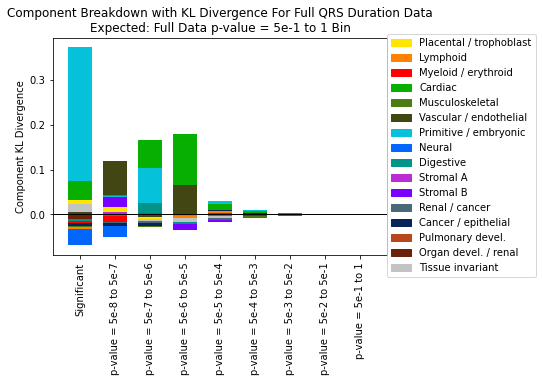

In [92]:
fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

qrs_duration_sigdata_kl1_sorted = np.argsort(-np.absolute(qrs_duration_sigdata_kl1))
for i in qrs_duration_sigdata_kl1_sorted:
    plt.bar(dataset[0], qrs_duration_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

qrs_duration_fulldata_kl2_sorted = np.argsort(-np.absolute(qrs_duration_fulldata_kl2))
for i in qrs_duration_fulldata_kl2_sorted:
    plt.bar(dataset[1], qrs_duration_fulldata_kl2[i], width=width, label=comps[i], color=color[i])
    
qrs_duration_fulldata_kl3_sorted = np.argsort(-np.absolute(qrs_duration_fulldata_kl3))
for i in qrs_duration_fulldata_kl3_sorted:
    plt.bar(dataset[2], qrs_duration_fulldata_kl3[i], width=width, label=comps[i], color=color[i])

qrs_duration_fulldata_kl4_sorted = np.argsort(-np.absolute(qrs_duration_fulldata_kl4))
for i in qrs_duration_fulldata_kl4_sorted:
    plt.bar(dataset[3], qrs_duration_fulldata_kl4[i], width=width, label=comps[i], color=color[i])

qrs_duration_fulldata_kl5_sorted = np.argsort(-np.absolute(qrs_duration_fulldata_kl5))
for i in qrs_duration_fulldata_kl5_sorted:
    plt.bar(dataset[4], qrs_duration_fulldata_kl5[i], width=width, label=comps[i], color=color[i])

qrs_duration_fulldata_kl6_sorted = np.argsort(-np.absolute(qrs_duration_fulldata_kl6))
for i in qrs_duration_fulldata_kl6_sorted:
    plt.bar(dataset[5], qrs_duration_fulldata_kl6[i], width=width, label=comps[i], color=color[i])

qrs_duration_fulldata_kl7_sorted = np.argsort(-np.absolute(qrs_duration_fulldata_kl7))
for i in qrs_duration_fulldata_kl7_sorted:
    plt.bar(dataset[6], qrs_duration_fulldata_kl7[i], width=width, label=comps[i], color=color[i])

qrs_duration_fulldata_kl8_sorted = np.argsort(-np.absolute(qrs_duration_fulldata_kl8))
for i in qrs_duration_fulldata_kl8_sorted:
    plt.bar(dataset[7], qrs_duration_fulldata_kl8[i], width=width, label=comps[i], color=color[i])

qrs_duration_fulldata_kl9_sorted = np.argsort(-np.absolute(qrs_duration_fulldata_kl9))
for i in qrs_duration_fulldata_kl9_sorted:
    plt.bar(dataset[8], qrs_duration_fulldata_kl9[i], width=width, label=comps[i], color=color[i])


    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For Full QRS Duration Data\nExpected: Full Data p-value = 5e-1 to 1 Bin')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

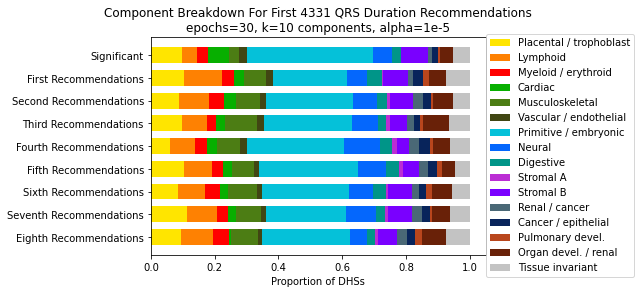

In [93]:
dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width = 0.7

fig = plt.figure()
fig.patch.set_facecolor('white')

left_num = 0
for i in range(len(qrs_duration_recs_8_comp_breakdown)):
    plt.barh(dataset[8], qrs_duration_recs_8_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_recs_8_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_recs_7_comp_breakdown)):
    plt.barh(dataset[7], qrs_duration_recs_7_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_recs_7_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_recs_6_comp_breakdown)):
    plt.barh(dataset[6], qrs_duration_recs_6_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_recs_6_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_recs_5_comp_breakdown)):
    plt.barh(dataset[5], qrs_duration_recs_5_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_recs_5_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_recs_4_comp_breakdown)):
    plt.barh(dataset[4], qrs_duration_recs_4_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_recs_4_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_recs_3_comp_breakdown)):
    plt.barh(dataset[3], qrs_duration_recs_3_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_recs_3_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_recs_2_comp_breakdown)):
    plt.barh(dataset[2], qrs_duration_recs_2_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_recs_2_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_recs_1_comp_breakdown)):
    plt.barh(dataset[1], qrs_duration_recs_1_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_recs_1_comp_breakdown[i]

left_num = 0
for i in range(len(qrs_duration_kp_comp_breakdown)):
    plt.barh(dataset[0], qrs_duration_kp_comp_breakdown[i], width, label=comps[i], color=color[i], left=left_num)
    left_num += qrs_duration_kp_comp_breakdown[i]


plt.xlabel('Proportion of DHSs')
plt.title('Component Breakdown For First 4331 QRS Duration Recommendations\nepochs=30, k=10 components, alpha=1e-5')
plt.legend(comps, loc = (1, -0.1))

plt.show()

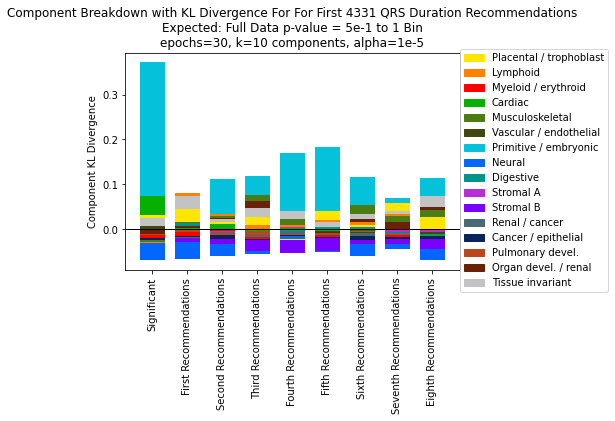

In [94]:
fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'Recommendations 1-100', 'Recommendations 101-200', 'Recommendations 201-300', 'Recommendations 301-400', 'Recommendations 401-500', 'Recommendations 501-600', 'Recommendations 601-700', 'Recommendations 701-800']
# dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

qrs_duration_sigdata_kl1_sorted = np.argsort(-np.absolute(qrs_duration_sigdata_kl1))
for i in qrs_duration_sigdata_kl1_sorted:
    plt.bar(dataset[0], qrs_duration_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl2_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl2))
for i in qrs_duration_recs_kl2_sorted:
    plt.bar(dataset[1], qrs_duration_recs_kl2[i], width=width, label=comps[i], color=color[i])
    
qrs_duration_recs_kl3_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl3))
for i in qrs_duration_recs_kl3_sorted:
    plt.bar(dataset[2], qrs_duration_recs_kl3[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl4_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl4))
for i in qrs_duration_recs_kl4_sorted:
    plt.bar(dataset[3], qrs_duration_recs_kl4[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl5_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl5))
for i in qrs_duration_recs_kl5_sorted:
    plt.bar(dataset[4], qrs_duration_recs_kl5[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl6_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl6))
for i in qrs_duration_recs_kl6_sorted:
    plt.bar(dataset[5], qrs_duration_recs_kl6[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl7_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl7))
for i in qrs_duration_recs_kl7_sorted:
    plt.bar(dataset[6], qrs_duration_recs_kl7[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl8_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl8))
for i in qrs_duration_recs_kl8_sorted:
    plt.bar(dataset[7], qrs_duration_recs_kl8[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl9_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl9))
for i in qrs_duration_recs_kl9_sorted:
    plt.bar(dataset[8], qrs_duration_recs_kl9[i], width=width, label=comps[i], color=color[i])

    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For For First 4331 QRS Duration Recommendations\nExpected: Full Data p-value = 5e-1 to 1 Bin\nepochs=30, k=10 components, alpha=1e-5')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()

/tmp/ipykernel_173386/3640538986.py:14: RuntimeWarning: invalid value encountered in true_divide
  qrs_duration_sigdata_kl1 = p1*np.log2(p1/q)
/tmp/ipykernel_173386/3640538986.py:15: RuntimeWarning: divide by zero encountered in true_divide
  qrs_duration_recs_kl2 = p2*np.log2(p2/q)
/tmp/ipykernel_173386/3640538986.py:16: RuntimeWarning: divide by zero encountered in true_divide
  qrs_duration_recs_kl3 = p3*np.log2(p3/q)
/tmp/ipykernel_173386/3640538986.py:17: RuntimeWarning: divide by zero encountered in true_divide
  qrs_duration_recs_kl4 = p4*np.log2(p4/q)
/tmp/ipykernel_173386/3640538986.py:18: RuntimeWarning: divide by zero encountered in true_divide
  qrs_duration_recs_kl5 = p5*np.log2(p5/q)
/tmp/ipykernel_173386/3640538986.py:19: RuntimeWarning: divide by zero encountered in true_divide
  qrs_duration_recs_kl6 = p6*np.log2(p6/q)
/tmp/ipykernel_173386/3640538986.py:20: RuntimeWarning: divide by zero encountered in true_divide
  qrs_duration_recs_kl7 = p7*np.log2(p7/q)
/tmp/ipyker

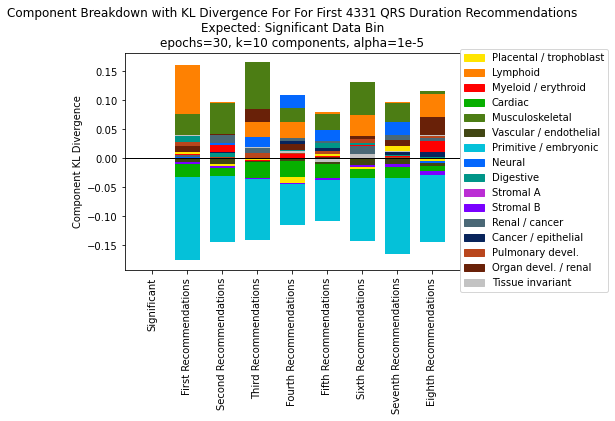

In [95]:
q = np.array(qrs_duration_kp_comp_breakdown)

#KL divergence of recommendations (relative to qrs_duration_kp_comp_breakdown)
p1 = np.array(qrs_duration_kp_comp_breakdown)
p2 = np.array(qrs_duration_recs_1_comp_breakdown)
p3 = np.array(qrs_duration_recs_2_comp_breakdown)
p4 = np.array(qrs_duration_recs_3_comp_breakdown)
p5 = np.array(qrs_duration_recs_4_comp_breakdown)
p6 = np.array(qrs_duration_recs_5_comp_breakdown)
p7 = np.array(qrs_duration_recs_6_comp_breakdown)
p8 = np.array(qrs_duration_recs_7_comp_breakdown)
p9 = np.array(qrs_duration_recs_8_comp_breakdown)

qrs_duration_sigdata_kl1 = p1*np.log2(p1/q)
qrs_duration_recs_kl2 = p2*np.log2(p2/q)
qrs_duration_recs_kl3 = p3*np.log2(p3/q)
qrs_duration_recs_kl4 = p4*np.log2(p4/q)
qrs_duration_recs_kl5 = p5*np.log2(p5/q)
qrs_duration_recs_kl6 = p6*np.log2(p6/q)
qrs_duration_recs_kl7 = p7*np.log2(p7/q)
qrs_duration_recs_kl8 = p8*np.log2(p8/q)
qrs_duration_recs_kl9 = p9*np.log2(p9/q)

fig = plt.figure()
fig.patch.set_facecolor('white')

dataset = ['Significant', 'First Recommendations', 'Second Recommendations', 'Third Recommendations', 'Fourth Recommendations', 'Fifth Recommendations', 'Sixth Recommendations', 'Seventh Recommendations', 'Eighth Recommendations']
# dataset = ['Significant', 'Recommendations 1-100', 'Recommendations 101-200', 'Recommendations 201-300', 'Recommendations 301-400', 'Recommendations 401-500', 'Recommendations 501-600', 'Recommendations 601-700', 'Recommendations 701-800']
# dataset = ['Significant', 'p-value = 5e-8 to 5e-7', 'p-value = 5e-7 to 5e-6', 'p-value = 5e-6 to 5e-5', 'p-value = 5e-5 to 5e-4', 'p-value = 5e-4 to 5e-3', 'p-value = 5e-3 to 5e-2', 'p-value = 5e-2 to 5e-1', 'p-value = 5e-1 to 1']

width=0.7

qrs_duration_sigdata_kl1_sorted = np.argsort(-np.absolute(qrs_duration_sigdata_kl1))
for i in qrs_duration_sigdata_kl1_sorted:
    plt.bar(dataset[0], qrs_duration_sigdata_kl1[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl2_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl2))
for i in qrs_duration_recs_kl2_sorted:
    plt.bar(dataset[1], qrs_duration_recs_kl2[i], width=width, label=comps[i], color=color[i])
    
qrs_duration_recs_kl3_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl3))
for i in qrs_duration_recs_kl3_sorted:
    plt.bar(dataset[2], qrs_duration_recs_kl3[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl4_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl4))
for i in qrs_duration_recs_kl4_sorted:
    plt.bar(dataset[3], qrs_duration_recs_kl4[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl5_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl5))
for i in qrs_duration_recs_kl5_sorted:
    plt.bar(dataset[4], qrs_duration_recs_kl5[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl6_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl6))
for i in qrs_duration_recs_kl6_sorted:
    plt.bar(dataset[5], qrs_duration_recs_kl6[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl7_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl7))
for i in qrs_duration_recs_kl7_sorted:
    plt.bar(dataset[6], qrs_duration_recs_kl7[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl8_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl8))
for i in qrs_duration_recs_kl8_sorted:
    plt.bar(dataset[7], qrs_duration_recs_kl8[i], width=width, label=comps[i], color=color[i])

qrs_duration_recs_kl9_sorted = np.argsort(-np.absolute(qrs_duration_recs_kl9))
for i in qrs_duration_recs_kl9_sorted:
    plt.bar(dataset[8], qrs_duration_recs_kl9[i], width=width, label=comps[i], color=color[i])

    
plt.xticks(rotation = 90)
plt.ylabel('Component KL Divergence')
plt.title('Component Breakdown with KL Divergence For For First 4331 QRS Duration Recommendations\nExpected: Significant Data Bin\nepochs=30, k=10 components, alpha=1e-5')
handles = list(plt.Rectangle((0,0),1,1, color=c) for c in color)
plt.legend(handles, comps, loc = (1, -0.1))
plt.axhline(y=0,linewidth=1, color='k')
plt.show()